In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving supplier_recommender_textile.xlsx to supplier_recommender_textile (1).xlsx


# **Dados Quantitativos** - Normalização dos dados

In [ ]:
# Como o Perfomance Band é uma variável qualitativa, esta parte do código lê os dados de fornecedores, filtra apenas algumas categorias de desempenho, remove valores faltantes (linhas vazias) e seleciona variáveis importantes. Em seguida, normaliza esses dados

from sklearn.preprocessing import StandardScaler

suppliers_df = pd.read_excel("/content/supplier_recommender_textile (1).xlsx", sheet_name="SUPPLIERS")
plot_order = ['POOR', 'AVERAGE', 'GOOD']
suppliers_df_cleaned = suppliers_df[suppliers_df['performance_band'].isin(plot_order)]
predictors_quanti = [
    "n_awards",                    # F=279 — mais discriminativa
    "price_index_vs_market",       # F=178
    "sustainability_score",        # F=92
    "defect_rate_pct",             # F=89
    "relationship_years",          # F=71
    "monthly_capacity_units",      # F=69
    "on_time_delivery_pct",        # F=68
    "avg_rating",                  # F=68
    "financial_risk_prob_default", # F robusto
    "co2_kg_per_unit",
    "n_events",
    "avg_lead_time_days",
]

df_clean = suppliers_df_cleaned.dropna(subset=predictors_quanti + ['avg_rating', 'performance_band']).copy()

X = df_clean[predictors_quanti]
X_normalized = StandardScaler().fit_transform(X)


print("Célula 1: Dados normalizados.")

print(f"Total de fornecedores na análise: {len(suppliers_df_cleaned)}")
print(f"Bandas de performance a serem analisadas: {plot_order}")

Célula 1: Dados normalizados.
Total de fornecedores na análise: 460
Bandas de performance a serem analisadas: ['POOR', 'AVERAGE', 'GOOD']


In [ ]:
# Lembrando que X = df_clean[predictors_quanti], logo esta parte do código normaliza as preditoras numéricas

X_normalized

array([[-0.54863771, -0.30885239, -1.99278593, ...,  2.10383579,
        -1.23899893,  0.55997224],
       [-0.54863771,  0.38324444,  0.08364125, ..., -0.30182295,
        -0.93437358, -0.70737619],
       [-0.54863771, -0.39536449,  0.63328374, ..., -0.59422346,
        -0.71678406,  1.0412438 ],
       ...,
       [-0.54863771, -0.6549008 , -1.87064316, ...,  1.1402432 ,
        -1.45658845,  0.81665041],
       [-0.42023974,  0.29673234,  0.75542651, ...,  0.49563299,
        -0.80381987, -0.72341857],
       [ 2.40451563, -0.74141291,  0.45006957, ...,  1.53232571,
         1.93780819, -1.15656297]])

# **Aprendizado não supervisionado**


Variância Explicada:
   Componente  Variancia_Explicada  Variancia_Acumulada
0         PC1             0.276751             0.276751
1         PC2             0.232997             0.509748
2         PC3             0.084708             0.594456
3         PC4             0.069766             0.664222
4         PC5             0.059820             0.724042
5         PC6             0.056284             0.780326
6         PC7             0.051155             0.831481
7         PC8             0.045568             0.877049
8         PC9             0.040585             0.917634
9        PC10             0.038735             0.956369
10       PC11             0.025187             0.981555
11       PC12             0.018445             1.000000


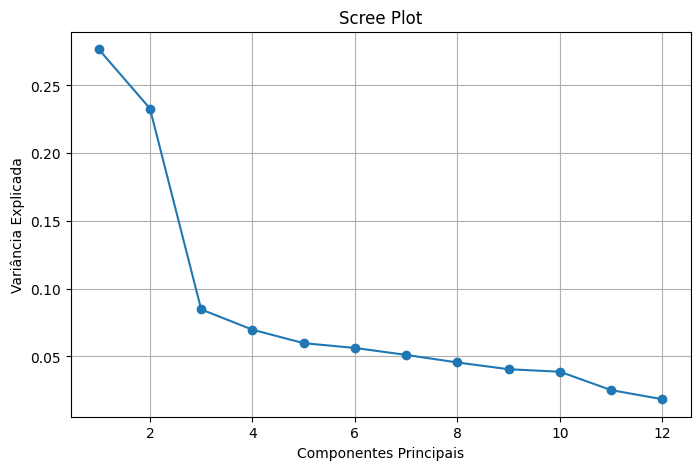

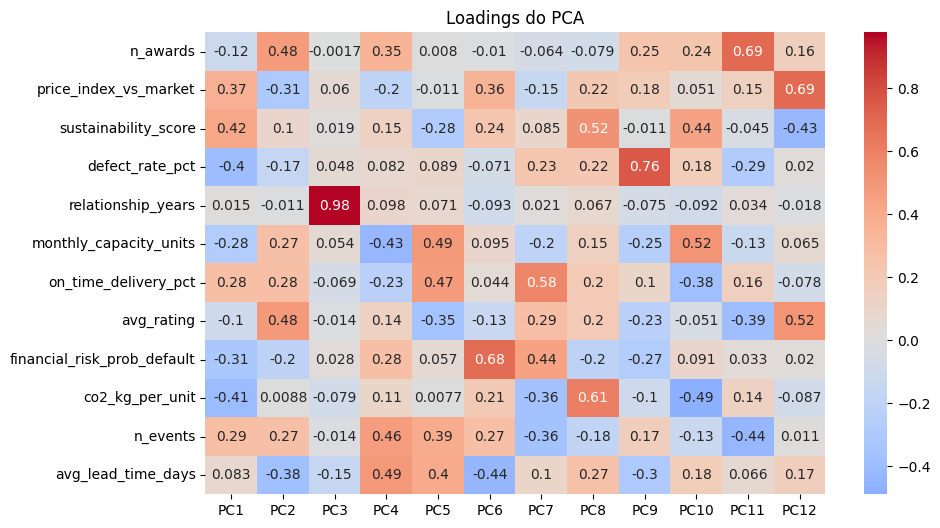

In [ ]:
# =========================
# SELEÇÃO DAS FEATURES
# =========================

# Using 'predictors_quanti' from the existing notebook context
# X_normalized already contains these features in the correct order
features = predictors_quanti

# The data X_normalized is already standardized from previous steps.
# We will use X_normalized directly for PCA.
X_scaled = X_normalized

# =========================
# PCA
# =========================

pca = PCA() # Initialize PCA without specifying n_components to get all components

X_pca = pca.fit_transform(X_scaled)

# =========================
# VARIÂNCIA EXPLICADA
# =========================

explained_variance = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(len(features))],
    'Variancia_Explicada': pca.explained_variance_ratio_,
    'Variancia_Acumulada': np.cumsum(pca.explained_variance_ratio_)
})

print("\nVariância Explicada:")
print(explained_variance)

# =========================
# LOADINGS
# =========================

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(features))],
    index=features
)

#print("\nLoadings:")
#print(loadings)

# =========================
# CONTRIBUIÇÃO ABSOLUTA
# =========================

contribuicao = loadings.abs()

#print("\nContribuição Absoluta:")
#print(contribuicao)

# =========================
# TOP FEATURES POR COMPONENTE
# =========================

for pc in loadings.columns:
    #print(f"\nTop features - {pc}")

    top = contribuicao[pc].sort_values(ascending=False)

    #print(top)

# =========================
# SCREE PLOT
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(features)+1),
    pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel('Componentes Principais')
plt.ylabel('Variância Explicada')
plt.title('Scree Plot')

plt.grid(True)
plt.show()

# =========================
# HEATMAP DOS LOADINGS
# =========================

plt.figure(figsize=(10,6))

sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title('Loadings do PCA')
plt.show()

**Possíveis variáveis redundantes:** Sustainability_score e co2_per_unit, n_awards e avg_rating

**Interpretação de cada componente baseado nos Loadings:**

Segundo o gráfico de Loadings:
Quanto mais perto de +1 a assiação é mais positia e quando mais perto de -1 a associação é mais negativa e quanto mais perto de 0, há pouca influência.

PC1: Sustentabilidade e competitividade (aumenta) x emissões e defeitos (diminui)
- Valores altos de PC1: empresas mais sustentáveis e com menor taxa de defeito
- Valores baixos de PC1: empresas com mais emissões e mais defeitos

PC2: Reconhecimento e reputação de mercado
- Valores altos de PC2: Empresas mais reconhecidas e bem avalidas, mesmo sem sere as mais sustentáveis ou produtivas
- Empresas sustentáveis, mas pouco conhecidas ou muito reconhcidas, mas não tão sustentáveis

PC3: Dominante é o tempo de relacionamento
- Variável independente
- Empresas antigas e novas aparecem espalhadas por vários níveis de qualidade, sustentabilidade e reputação.

PC4: Complexidade operacional
- Valores altos de PC4: empresas que podem estar sofrendo com maior pressão operacional

PC5: Eficiência operacional e capacidade produtiva (capacidade de operar em larga escala mantendo desempenho)
- Valores altos de PC5: Empresas que conseguem crescer sem perder a eficiência e pontualidade

PC6: Maior probabilidade de inadimplência
- Maiores valores de P6: Empresas com maior risco de inadimplência
- Esta separando empresas financeiramente robustas das mais vulneráveis

PC7:Confiabilidade operacional
- Normalmente esperaríamos risco financeiro e desempenho operacional caminhando em direções opostas. Aqui ambos aparecem positivos.
- Subconjuntode empresas que apesar do risco financeiro, mantem boa perfomance operacional

**PC8: Sustentabilidade e emissões aparecem juntas
- Empresas em que programas de sustentabilidade coexistem com níveis elevados de emissão. Interessate, pois existem grupos de empresas que possuem certificações, programas ESG, alto sustanability score, mas ainda possuem emissões altas.

PC9: Dominante é taxa de defitos
- Maiores valores de PC9: Taxas de defeito ebm diferentes da média

PC10: Capacidade produtiva x Intensidade de emissões
- Empresas com maiores operações, possuem menores emissões relativas por unidade

PC11: Dominante é reconhecimento externo (prêmios)
- Mede apenas o quanto a empresa é premiada

PC12: Empresas mais caras e bem avaliadas, mas não sustentáveis
- Empresas que cobram mais caro,r recebem avaliações melhores, mas não necessariamente apresentam melhores sustentabilidades

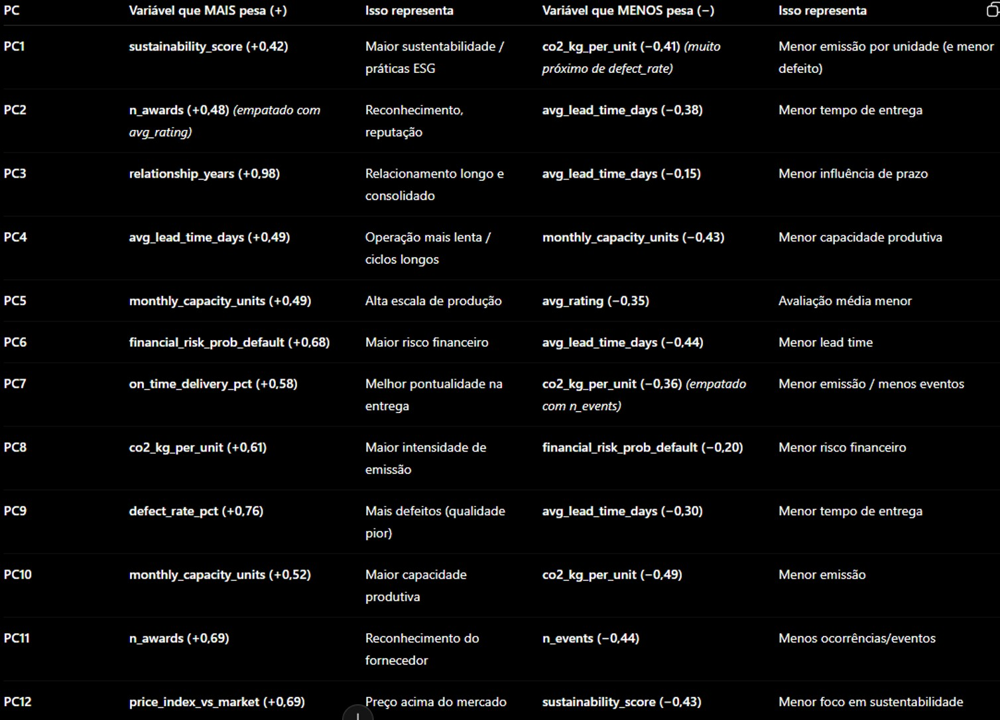

Pensando em focar apenas em PC1, PC2 e PC3, pois explicam boa parte do modelo e que oferecem melhores resultados de clusterização. No entento, podemos desconsiderar PC3, pois possui um loading muito alto, logo podemos tratá-la a parte como um variavel isolada. A pergunta que devemos fazer quando pensamos nela é: "Devemos escolher um fornecedor apenas pelo tempo de relacionamento?"

# **Analisando as possbilidades de números de Clusters:**

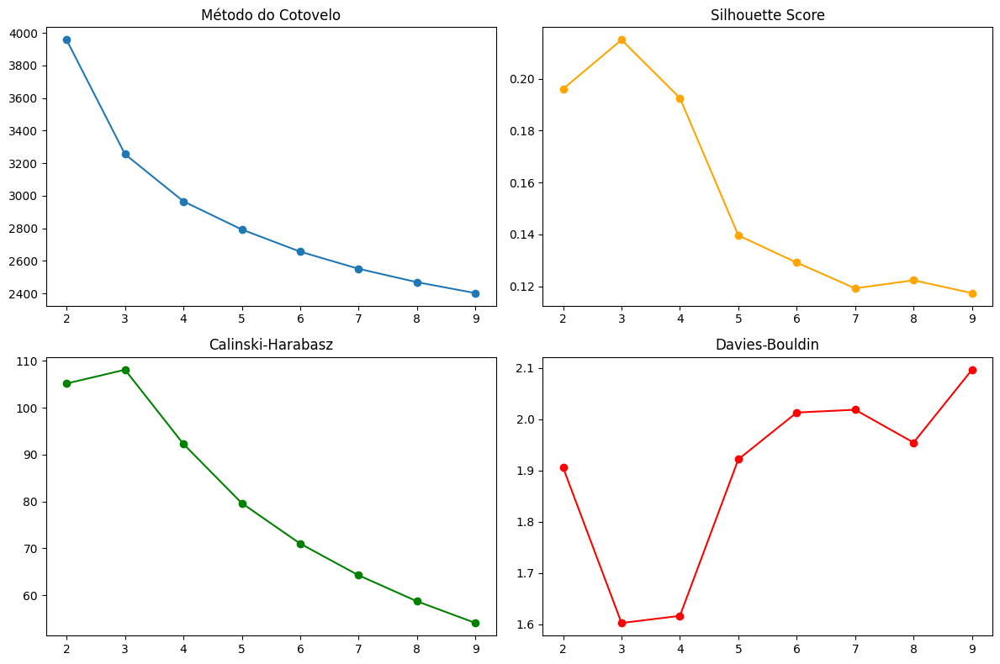

In [ ]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_range = range(2, 10)
metrics = {'Inércia': [], 'Silhouette': [], 'CH_Score': [], 'DB_Score': []}

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    metrics['Inércia'].append(km.inertia_)
    metrics['Silhouette'].append(silhouette_score(X_pca, km.labels_))
    metrics['CH_Score'].append(calinski_harabasz_score(X_pca, km.labels_))
    metrics['DB_Score'].append(davies_bouldin_score(X_pca, km.labels_))

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0,0].plot(k_range, metrics['Inércia'], 'o-'); axs[0,0].set_title('Método do Cotovelo')
axs[0,1].plot(k_range, metrics['Silhouette'], 'o-', color='orange'); axs[0,1].set_title('Silhouette Score')
axs[1,0].plot(k_range, metrics['CH_Score'], 'o-', color='green'); axs[1,0].set_title('Calinski-Harabasz')
axs[1,1].plot(k_range, metrics['DB_Score'], 'o-', color='red'); axs[1,1].set_title('Davies-Bouldin')
plt.tight_layout()
plt.show()

**Conclusão:**

-**Silhouette**

Maior valor em K=3.
Depois começa a cair continuamente.
Isso sugere que os clusters ficam menos separados à medida que você aumenta K.

-**Davies-Bouldin**

Menor valor em K=3.
K=4 é muito próximo.
A partir de K=5 piora bastante.

-**Calinski-Harabasz**

Maior valor em K=3.
Cai continuamente depois.


--- Clusterização com K=2 ---
Silhouette Score para K=2: 0.1961


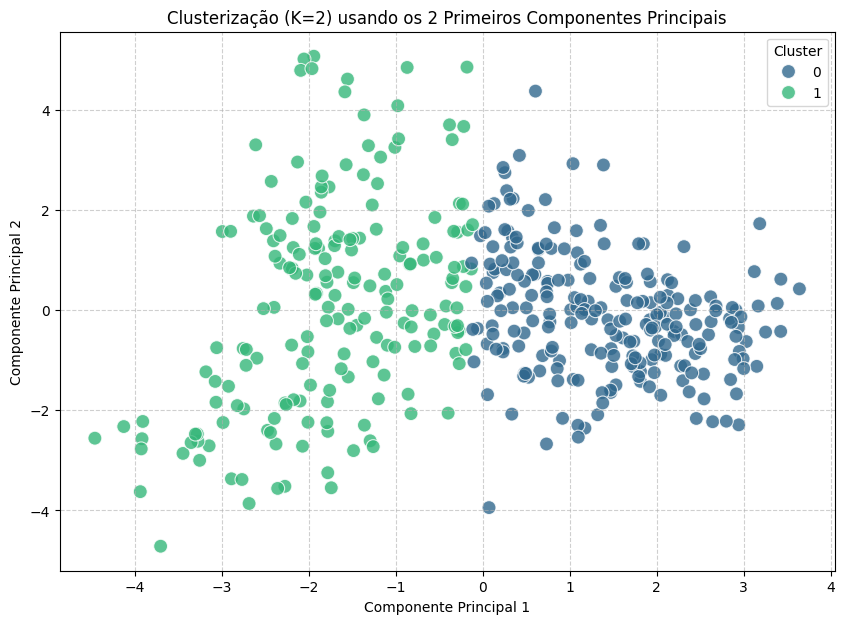


--- Clusterização com K=3 ---
Silhouette Score para K=3: 0.2150


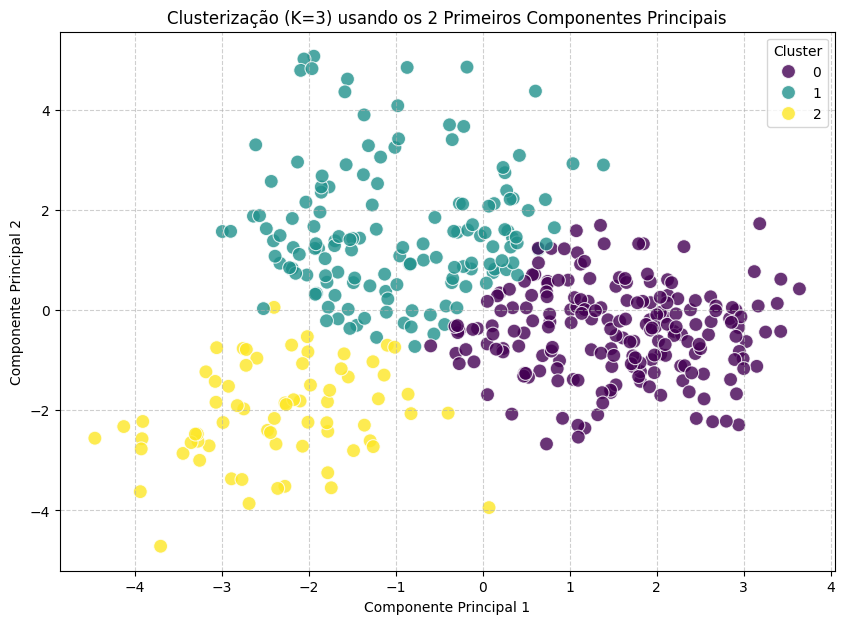


--- Clusterização com K=4 ---
Silhouette Score para K=4: 0.1926


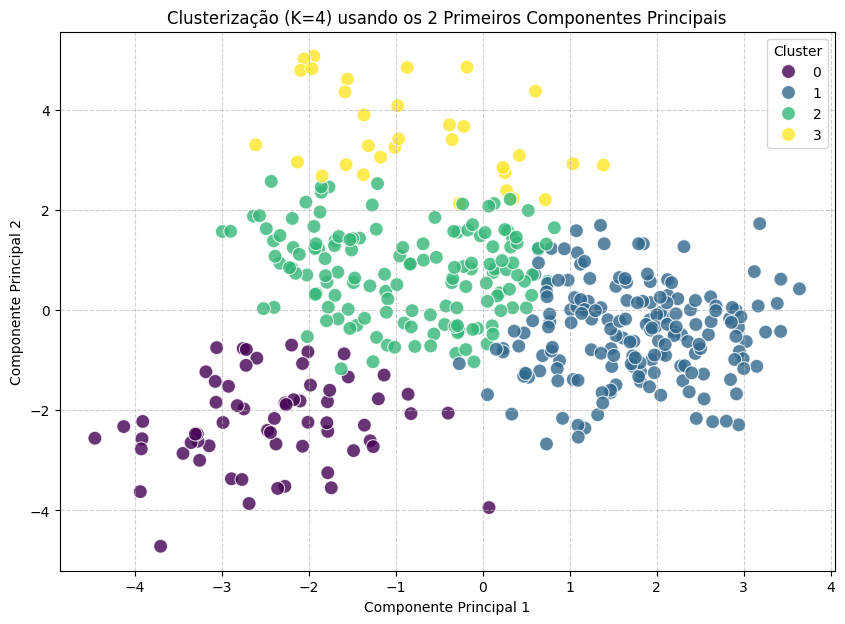


--- Clusterização com K=5 ---
Silhouette Score para K=5: 0.1396


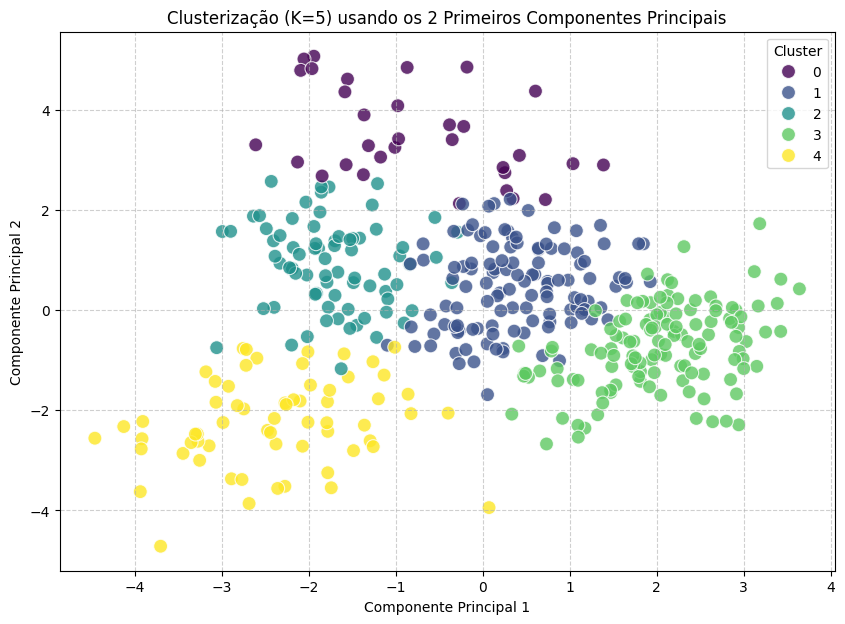


--- Clusterização com K=6 ---
Silhouette Score para K=6: 0.1292


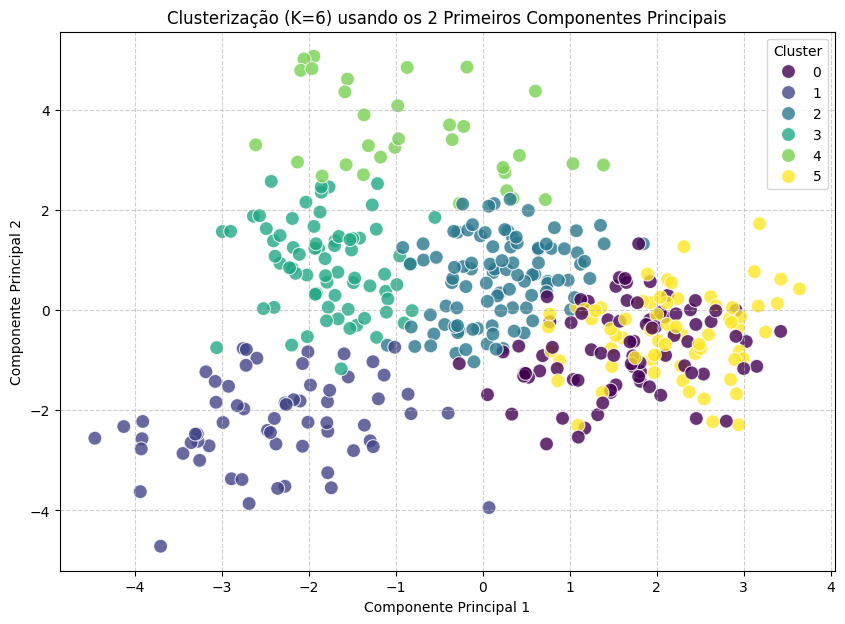

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [2, 3, 4, 5, 6]

for k in k_values:
    print(f"\n--- Clusterização com K={k} ---")

    # =========================
    # K-MEANS CLUSTERING
    # =========================

    # Usando TODAS as componentes principais para a clusterização
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init to suppress warning
    clusters = kmeans.fit_predict(X_pca) # Fit KMeans on ALL PCs

    # Calculate Silhouette Score usando TODAS as componentes principais
    current_silhouette_score = silhouette_score(X_pca, clusters)
    print(f"Silhouette Score para K={k}: {current_silhouette_score:.4f}")

    # Add cluster labels to the original clean DataFrame for potential further analysis
    # This part is optional if you only need the plot, but useful for further data analysis
    # df_clean_clustered = df_clean.copy()
    # df_clean_clustered[f'cluster_pca_k{k}'] = clusters

    # =========================
    # CLUSTERING PLOT
    # =========================

    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=X_pca[:, 0], # First Principal Component (for visualization)
        y=X_pca[:, 1], # Second Principal Component (for visualization)
        hue=clusters,  # Color by assigned cluster
        palette='viridis', # Choose a color palette
        s=100,         # Marker size
        alpha=0.8,     # Transparency
        edgecolor='w'  # White edge around markers
    )

    plt.title(f'Clusterização (K={k}) usando os 2 Primeiros Componentes Principais')
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

Podemos concluir que o melhor resultado é com K=3, tanto pelos métodos de Silhouette Score, Calinki e Davis que o melhor K=3. Assim como ao projetar os gráficos de clusterização, o melhor silhouette score de fato comprova que o melhor número de clusters seria 3 mesmo.

# **Interpretando cada cluster, com K=3:**

Para rotularmos os gráficos, pensamos como referência na matriz de portifólio, levando em consideração os resultados dos loadings. Desta forma, se K=3, para PC1 (eixo x) x PC2 (eixo y):

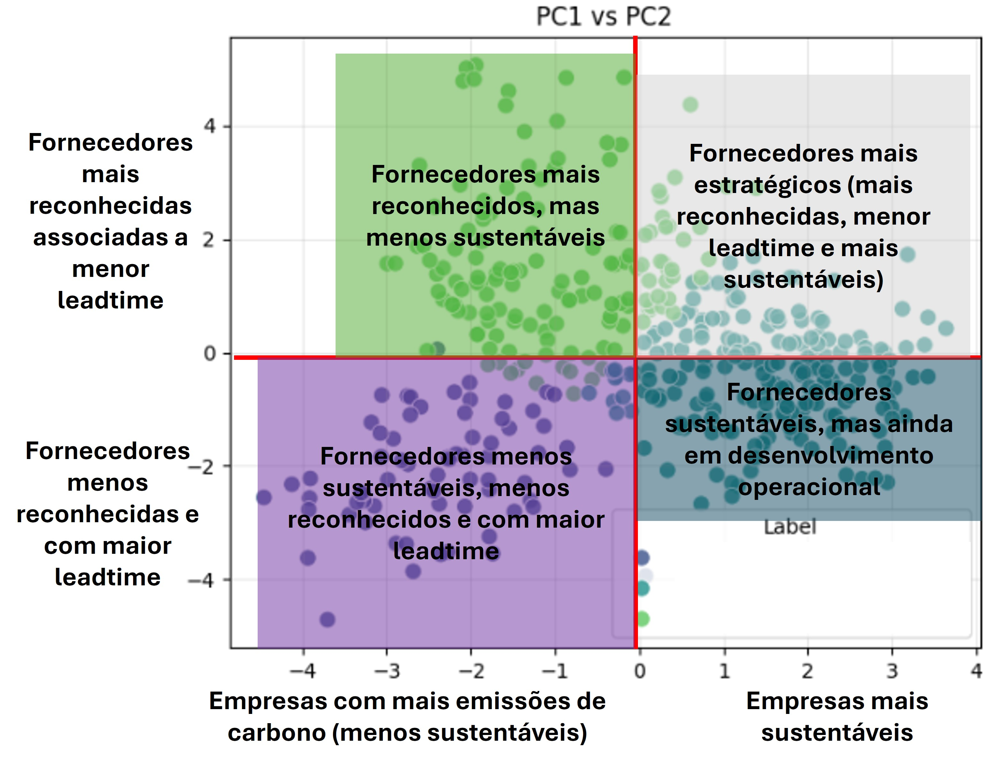

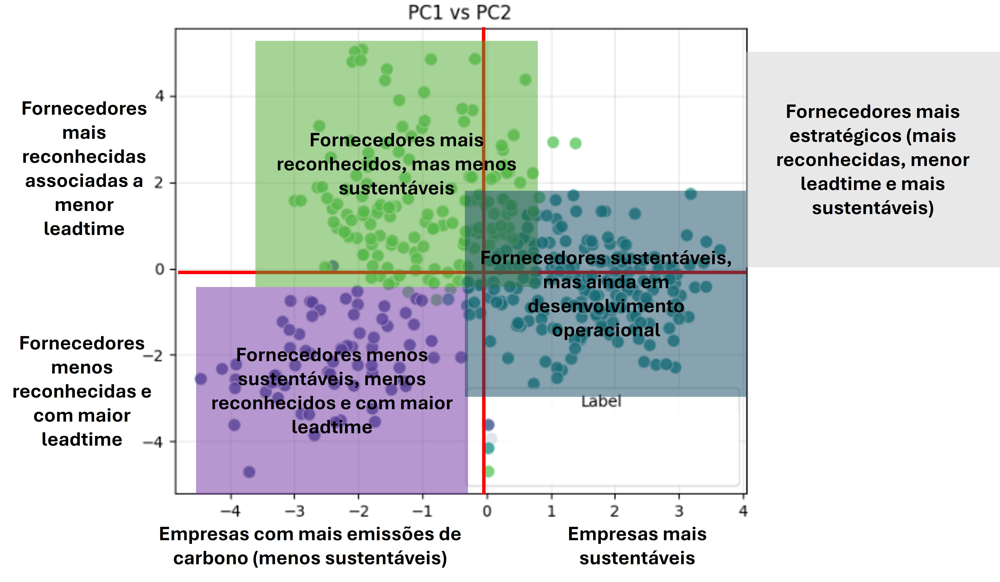

## Projetando em outros eixos:

Usando TODAS as componentes principais: PC1 até PC12





In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from itertools import combinations

# =====================================================
# 1. DEFINIÇÃO EXPLÍCITA DAS COMPONENTES USADAS
# =====================================================

# ✔ AQUI ESTÁ EXPLÍCITO QUE USAMOS TODAS AS PCs GERADAS
X_all_pcs = X_pca  # <- TODAS as componentes principais

n_components = X_all_pcs.shape[1]

print(f"Usando TODAS as componentes principais: PC1 até PC{n_components}")

# =====================================================
# 2. CLUSTERIZAÇÃO NO ESPAÇO COMPLETO DAS PCs
# =====================================================

k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_all_pcs)
# ✔ AQUI: usa TODAS as PCs ao mesmo tempo

df_clean['Cluster'] = clusters

# =====================================================
# 3. DATAFRAME DAS PCs (TODAS)
# =====================================================

pc_cols = [f'PC{i+1}' for i in range(n_components)]

df_pca = pd.DataFrame(
    X_all_pcs,
    columns=pc_cols
)

df_pca['Cluster'] = clusters

# =====================================================
# 4. RÓTULOS (FIXOS OU AUTOMÁTICOS)
# =====================================================

labels = {
    0: 'Líder de Mercado',
    1: 'Sustentável e Eficiente',
    2: 'Alto Risco e Baixa Eficiência'
}

df_pca['Label'] = df_pca['Cluster'].map(labels)

# =====================================================
# 5. FUNÇÃO DE PLOT (QUALQUER PAR DE PCs)
# =====================================================

def plot_all_pca(pcs, label_col='Label'):

    pairs = list(combinations(pcs, 2))

    n = len(pairs)
    cols = 3
    rows = (n // cols) + (n % cols > 0)

    plt.figure(figsize=(18, 5 * rows))

    for i, (x, y) in enumerate(pairs, 1):
        plt.subplot(rows, cols, i)

        sns.scatterplot(
            data=df_pca,
            x=x,
            y=y,
            hue=label_col,
            palette='viridis',
            s=70,
            alpha=0.8
        )

        plt.title(f'{x} vs {y}')
        plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

# =====================================================
# 6. USO (TODAS AS PCs AUTOMATICAMENTE)
# =====================================================

pcs_to_plot = pc_cols  # ✔ AQUI também usa TODAS as PCs

plot_all_pca(pcs_to_plot, label_col='Label')

**Conclusões imediatas:**

A análise de PCA mostrou que os dois primeiros componentes principais (PC1 e PC2) concentram a maior parte da variância dos dados e representam a estrutura mais importante do conjunto. Esses componentes não correspondem a variáveis isoladas, mas sim a combinações lineares das variáveis originais que sintetizam os principais padrões de variação. Já o PC3 aparece como uma dimensão mais específica e independente, fortemente associado a uma variável mais isolada, do tipo tempo de relacionamento, e por isso contribui menos para a estrutura geral dos dados.

Na análise de clusterização, observou-se que a melhor separação dos grupos ocorre quando os dados são projetados no plano formado por PC1 e PC2. Nesse espaço, os clusters ficam mais bem definidos, o que indica que esses componentes capturam de forma mais eficiente a estrutura global dos dados. Em contrapartida, quando se utiliza PC1 × PC3, a qualidade da separação diminui, pois o PC3 representa uma dimensão mais específica e não alinhada diretamente com a segmentação principal dos dados.

A interpretação dos clusters, baseada nas médias das variáveis originais, também se mostrou coerente com a estrutura observada no PCA. Isso indica que os grupos encontrados são principalmente influenciados pelas variáveis que mais contribuem para PC1 e PC2, reforçando que esses componentes representam os principais fatores de diferenciação entre as observações. Importante destacar que não se trata de “importância direta” das variáveis, mas sim do fato de que PC1 e PC2 agregam as variáveis mais relevantes em dimensões latentes dominantes.

O PC3, por sua vez, embora apresente forte carga em uma variável específica, não contribui significativamente para a separação global dos clusters. Ele adiciona mais uma camada interpretativa relacionada a um aspecto específico dos dados, mas não é determinante para a estrutura de segmentação.

# **PCA para Sub Datasets por Produto**

Realizando a separação por sub-bases:

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Check if an Excel file was uploaded and load it into df
# Corrected filename check based on 'uploaded' variable in kernel state
if 'supplier_recommender_textile (1).xlsx' in uploaded:
    df = pd.read_excel(uploaded['supplier_recommender_textile (1).xlsx'])
    print("DataFrame 'df' loaded successfully from uploaded Excel file.")
elif 'df_clean' in globals(): # Fallback to existing df_clean if df is not loaded and df_clean exists
    df = df_clean.copy()
    print("DataFrame 'df' assigned from 'df_clean'.")
elif 'suppliers_df_cleaned' in globals():
    df = suppliers_df_cleaned.copy()
    print("DataFrame 'df' assigned from 'suppliers_df_cleaned'.")
else:
    print("Error: No suitable DataFrame found to assign to 'df'. Please ensure 'df' or a similar DataFrame is loaded.")
    # Optionally, you might want to exit or raise an exception here if df is critical
    # For this adaptation, we assume df will be assigned by one of the above.

# VARIÁVEIS ESCOLHIDAS
# 'predictors_quanti' is expected to be defined in the global scope.
features = predictors_quanti

# DICIONÁRIO PARA SALVAR
normalized_datasets = {}

# Handle 'product_focus' for iteration
if 'product_focus' in df.columns:
    grouping_column = 'product_focus'
    unique_groups = df[grouping_column].unique()
    print(f"Agrupando por '{grouping_column}'. Grupos únicos encontrados: {unique_groups}")
else:
    print("Aviso: Coluna 'product_focus' não encontrada no DataFrame 'df'.")
    print("Prosseguindo sem agrupar por 'product_focus', normalizando o conjunto de dados completo como um único grupo.")
    grouping_column = None # No grouping will occur
    unique_groups = [None] # A single 'group' to iterate once through the entire dataframe

for group_value in unique_groups:
    if grouping_column:
        # Create subbase if grouping_column exists
        subbase = df[df[grouping_column] == group_value].copy()
        # Sanitize product_nome for variable names
        produto_nome = str(group_value).lower().replace(" ", "_").replace("&", "and").replace("/", "_").replace("-", "_")
    else:
        # If no grouping column, process the entire df as a single 'group'
        subbase = df.copy()
        produto_nome = "full_dataset" # Name for the single group

    # Selecionar variáveis
    X = subbase[features]

    # Normalização
    scaler = StandardScaler()

    # Handle cases where X might be empty for a group (e.g., if a group has no data for the features)
    if not X.empty:
        X_normalized = scaler.fit_transform(X)

        # Transformar em DataFrame
        X_normalized = pd.DataFrame(
            X_normalized,
            columns=features,
            index=subbase.index
        )

        nome_variavel = f"X_normalized_{produto_nome}"

        # Salvar no dicionário
        normalized_datasets[nome_variavel] = X_normalized

        # Criar variável automática no escopo global
        globals()[nome_variavel] = X_normalized

        print(f"{nome_variavel} criado com sucesso!")
    else:
        print(f"Pulando a normalização para o grupo '{group_value}' devido a uma sub-base vazia.")

/tmp/ipykernel_2083/962981895.py:7: FutureWarning: Passing bytes to 'read_excel' is deprecated and will be removed in a future version. To read from a byte string, wrap it in a `BytesIO` object.
  df = pd.read_excel(uploaded['supplier_recommender_textile (1).xlsx'])


DataFrame 'df' loaded successfully from uploaded Excel file.
Agrupando por 'product_focus'. Grupos únicos encontrados: ['Buttons' 'Cotton Fabric' 'Yarn' 'Dyes & Chemicals' 'Packaging'
 'Elastic & Trims' 'Polyester Fabric' 'Labels & Tags' 'Zippers' 'Denim'
 'Thread']
X_normalized_buttons criado com sucesso!
X_normalized_cotton_fabric criado com sucesso!
X_normalized_yarn criado com sucesso!
X_normalized_dyes_and_chemicals criado com sucesso!
X_normalized_packaging criado com sucesso!
X_normalized_elastic_and_trims criado com sucesso!
X_normalized_polyester_fabric criado com sucesso!
X_normalized_labels_and_tags criado com sucesso!
X_normalized_zippers criado com sucesso!
X_normalized_denim criado com sucesso!
X_normalized_thread criado com sucesso!


**As sub bases criadas são:**

X_normalized_buttons

X_normalized_cotton_fabric

X_normalized_yarn

X_normalized_dyes_and_chemicals

X_normalized_packaging

X_normalized_elastic_and_trims

X_normalized_polyester_fabric

X_normalized_labels_and_tags

X_normalized_zippers

X_normalized_denim

X_normalized_thread

# **K=2**


--- Processando dataset: X_normalized_buttons com K=2 ---


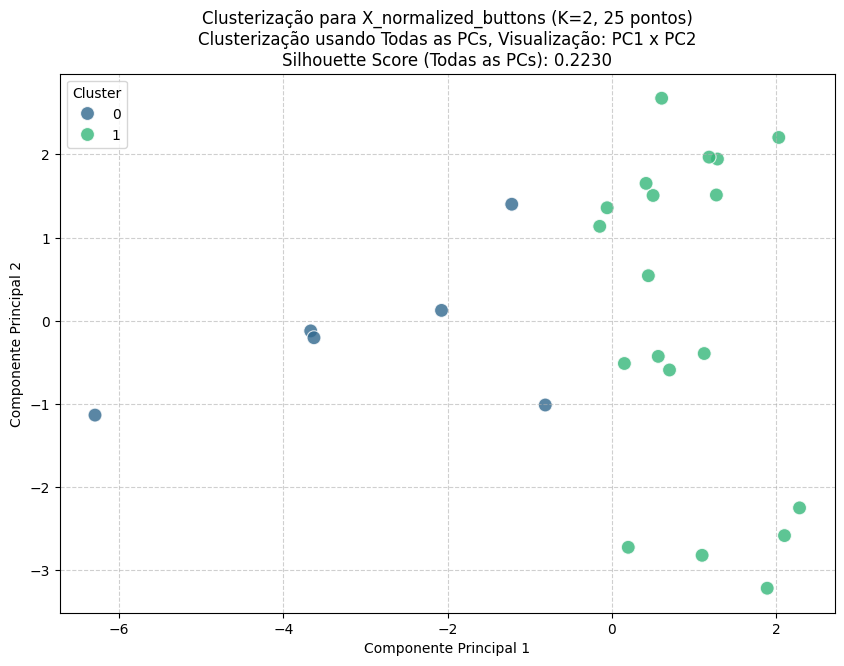


--- Processando dataset: X_normalized_cotton_fabric com K=2 ---
Encontrado NaN no dataset 'X_normalized_cotton_fabric'. Eliminando linhas com NaN...


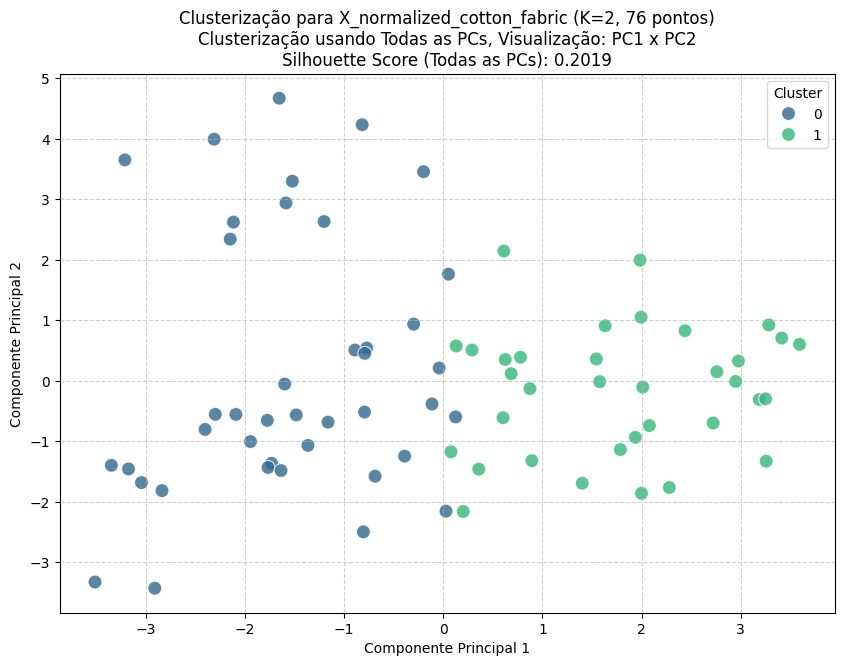


--- Processando dataset: X_normalized_yarn com K=2 ---
Encontrado NaN no dataset 'X_normalized_yarn'. Eliminando linhas com NaN...


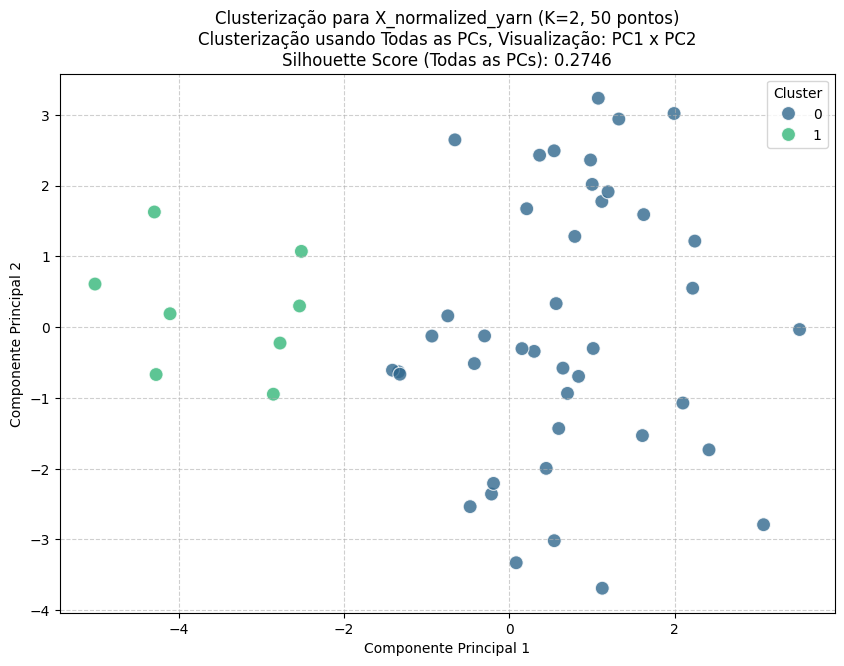


--- Processando dataset: X_normalized_dyes_and_chemicals com K=2 ---
Encontrado NaN no dataset 'X_normalized_dyes_and_chemicals'. Eliminando linhas com NaN...


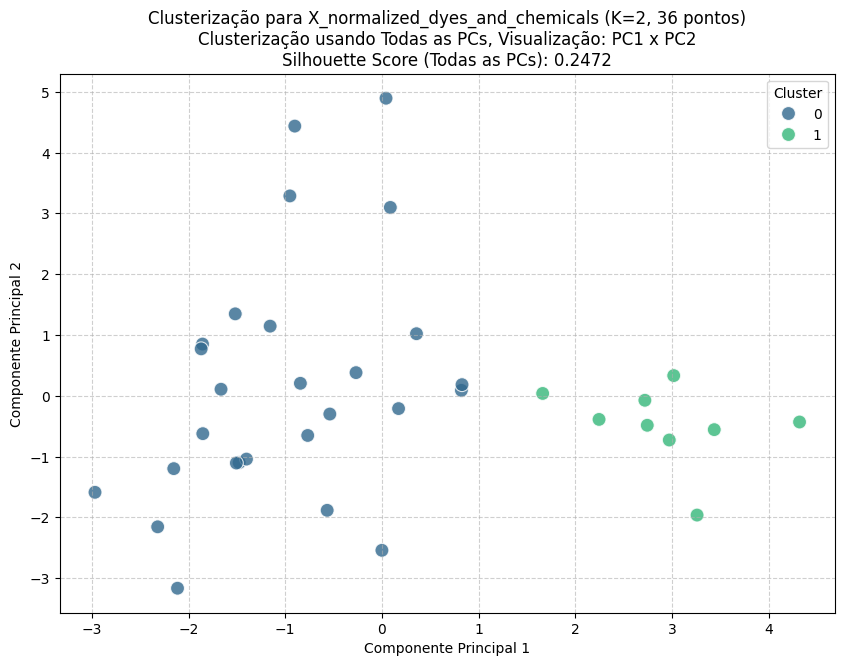


--- Processando dataset: X_normalized_packaging com K=2 ---
Encontrado NaN no dataset 'X_normalized_packaging'. Eliminando linhas com NaN...


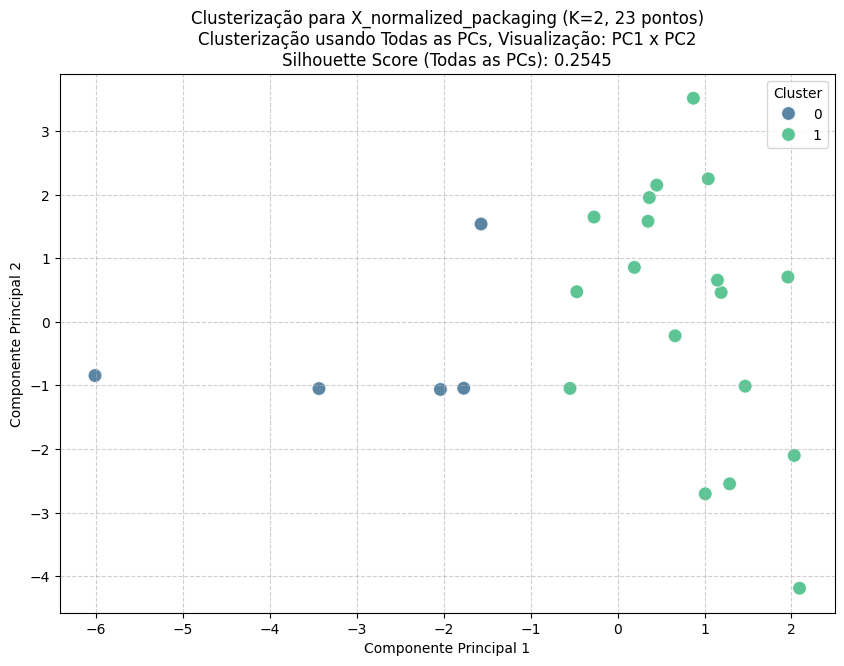


--- Processando dataset: X_normalized_elastic_and_trims com K=2 ---


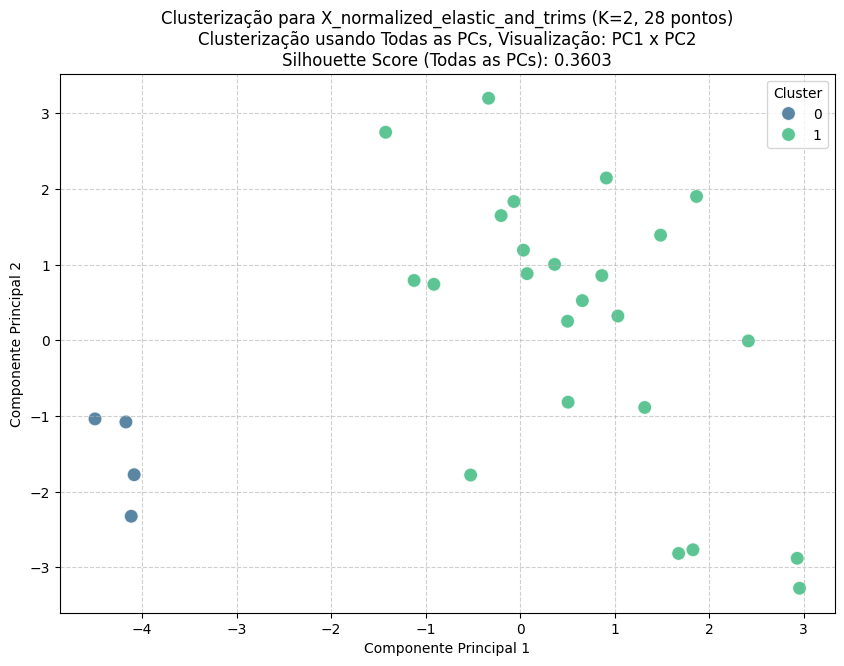


--- Processando dataset: X_normalized_polyester_fabric com K=2 ---
Encontrado NaN no dataset 'X_normalized_polyester_fabric'. Eliminando linhas com NaN...


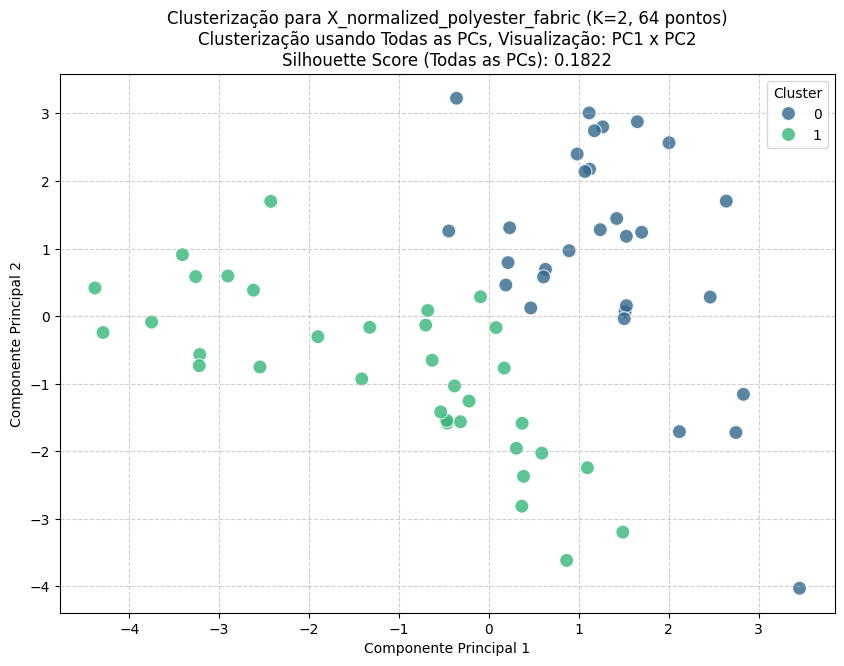


--- Processando dataset: X_normalized_labels_and_tags com K=2 ---
Encontrado NaN no dataset 'X_normalized_labels_and_tags'. Eliminando linhas com NaN...


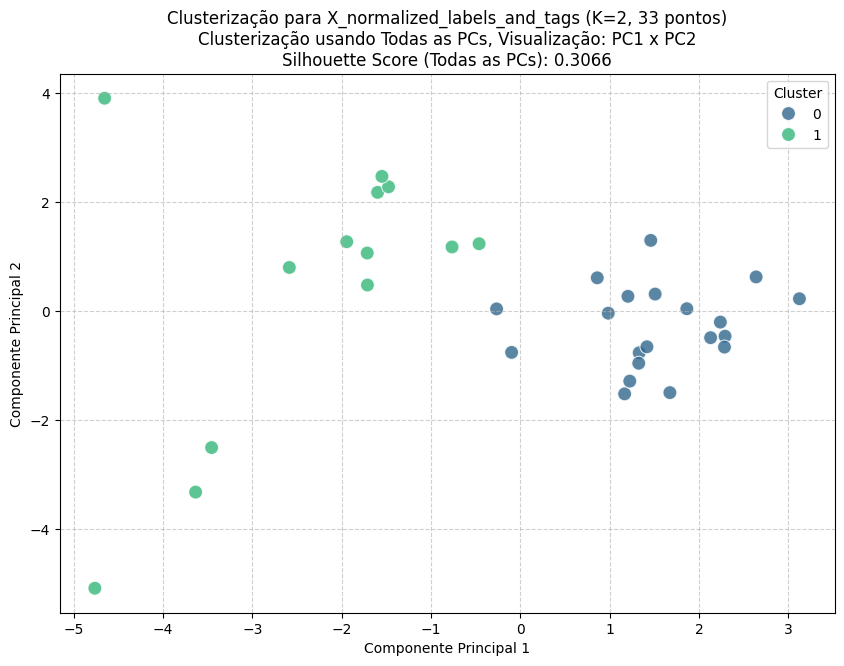


--- Processando dataset: X_normalized_zippers com K=2 ---
Encontrado NaN no dataset 'X_normalized_zippers'. Eliminando linhas com NaN...


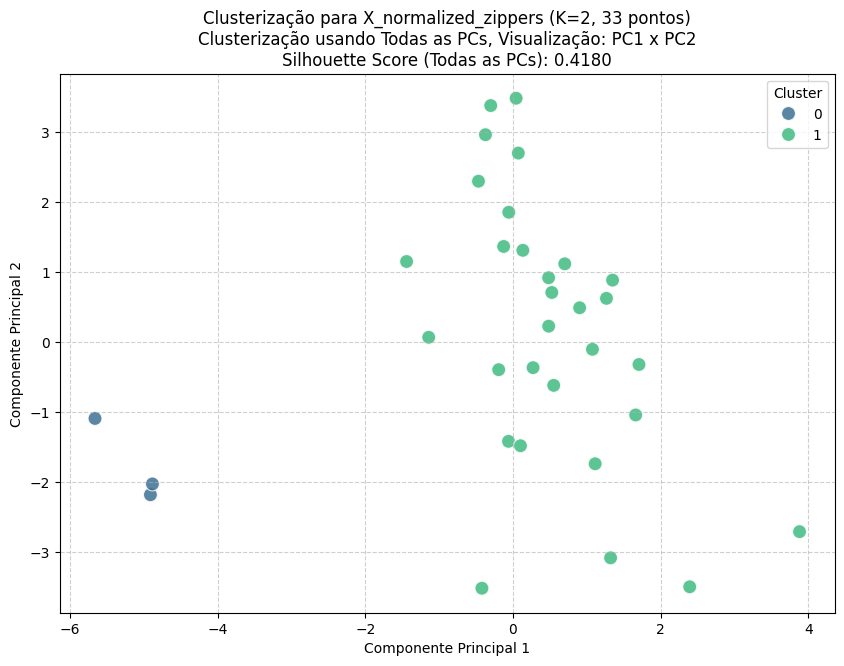


--- Processando dataset: X_normalized_denim com K=2 ---
Encontrado NaN no dataset 'X_normalized_denim'. Eliminando linhas com NaN...


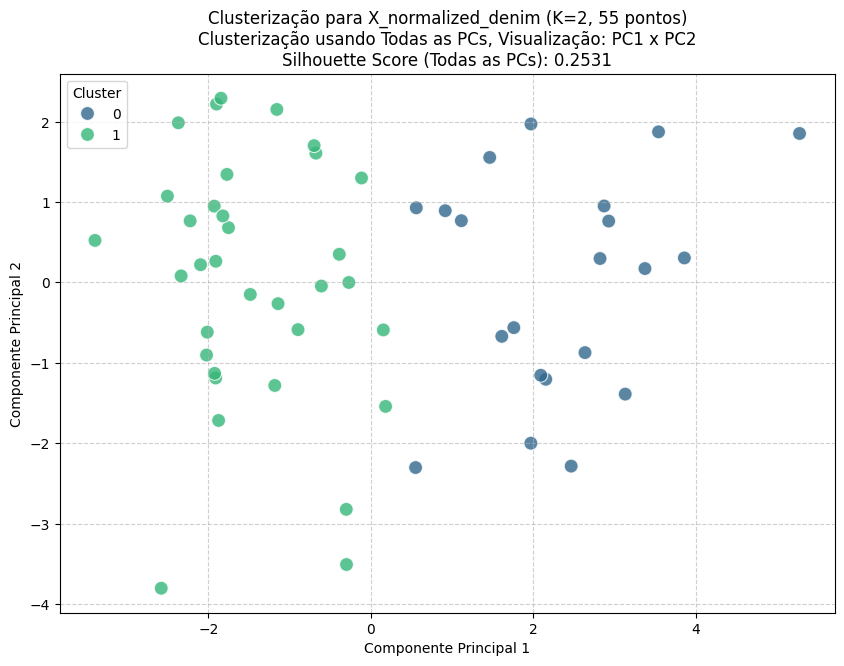


--- Processando dataset: X_normalized_thread com K=2 ---
Encontrado NaN no dataset 'X_normalized_thread'. Eliminando linhas com NaN...


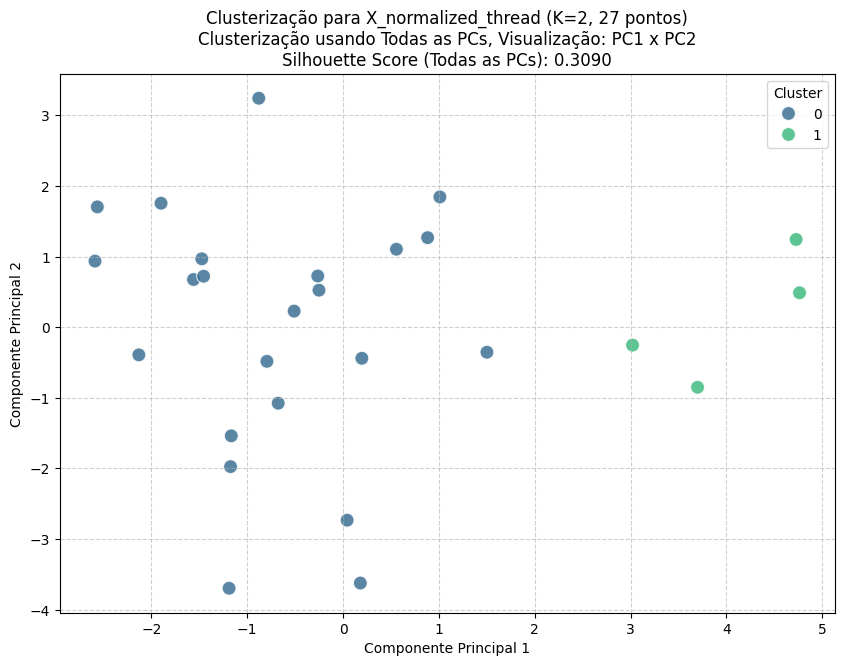

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Importar numpy para verificar NaNs
import pandas as pd # Garantir que pandas esteja importado para operações com DataFrame

k = 2 # Definindo K fixo em 2, conforme o contexto desta célula

# Itera sobre cada sub-dataset normalizado
for dataset_name, X_normalized_sub in normalized_datasets.items():
    print(f"\n--- Processando dataset: {dataset_name} com K={k} ---")

    # Verificar se o dataset não está vazio e tem amostras suficientes
    if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
        print(f"Aviso: Dataset '{dataset_name}' é muito pequeno ou vazio para PCA/Clusterização com K={k}. Pulando...")
        continue

    # === TRATAMENTO DE NaNs ===
    # Verificar se há NaNs e eliminá-los, se necessário
    if X_normalized_sub.isnull().sum().sum() > 0:
        print(f"Encontrado NaN no dataset '{dataset_name}'. Eliminando linhas com NaN...")
        X_normalized_sub = X_normalized_sub.dropna()
        # Após dropar, verificar novamente se o dataset ainda é válido para PCA/Clusterização
        if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
            print(f"Aviso: Após eliminar NaNs, o dataset '{dataset_name}' ficou muito pequeno ou vazio. Pulando...")
            continue
    # === FIM TRATAMENTO DE NaNs ===

    # Aplicar PCA para TODAS as componentes principais para a clusterização
    # n_components=None utiliza todas as componentes, até min(n_samples, n_features) - 1
    pca_full = PCA(n_components=None) # Usar todas as componentes para a clusterização
    X_pca_all_components = pca_full.fit_transform(X_normalized_sub)

    # K-Means Clustering usando TODAS as componentes principais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_sub = kmeans.fit_predict(X_pca_all_components) # Clusterizar usando todas as PCs

    # Calcular Silhouette Score usando TODAS as componentes principais
    if len(set(clusters_sub)) > 1 and X_pca_all_components.shape[0] > k:
        current_silhouette_score = silhouette_score(X_pca_all_components, clusters_sub)
        silhouette_str = f"Silhouette Score (Todas as PCs): {current_silhouette_score:.4f}"
    else:
        silhouette_str = "Silhouette Score: N/A (Não foi possível calcular ou apenas 1 cluster formado)"

    # Para visualização, usar apenas as duas primeiras componentes principais
    n_components_for_plot = min(2, X_pca_all_components.shape[1])
    if n_components_for_plot < 2:
        print(f"Aviso: Dataset '{dataset_name}' tem menos de 2 componentes para plotar. Pulando plotagem...")
        continue # Pula a plotagem, mas a clusterização já foi feita

    df_pca_plot = pd.DataFrame(
        X_pca_all_components[:, :n_components_for_plot], # Selecionar apenas as duas primeiras componentes para o plot
        columns=[f'PC{i+1}' for i in range(n_components_for_plot)],
        index=X_normalized_sub.index
    )

    # Adicionar os clusters ao DataFrame PCA para visualização
    df_pca_plot['Cluster'] = clusters_sub

    # Obter o número de pontos após o tratamento de NaNs
    num_points = df_pca_plot.shape[0]

    # Plotar os resultados
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=df_pca_plot['PC1'], # Primeira Componente Principal para visualização
        y=df_pca_plot['PC2'], # Segunda Componente Principal para visualização
        hue=df_pca_plot['Cluster'], # Colorir por cluster
        palette='viridis',
        s=100,
        alpha=0.8,
        edgecolor='w'
    )

    plt.title(f'Clusterização para {dataset_name} (K={k}, {num_points} pontos)\nClusterização usando Todas as PCs, Visualização: PC1 x PC2\n{silhouette_str}')
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **K=3**


--- Processando dataset: X_normalized_buttons com K=3 ---


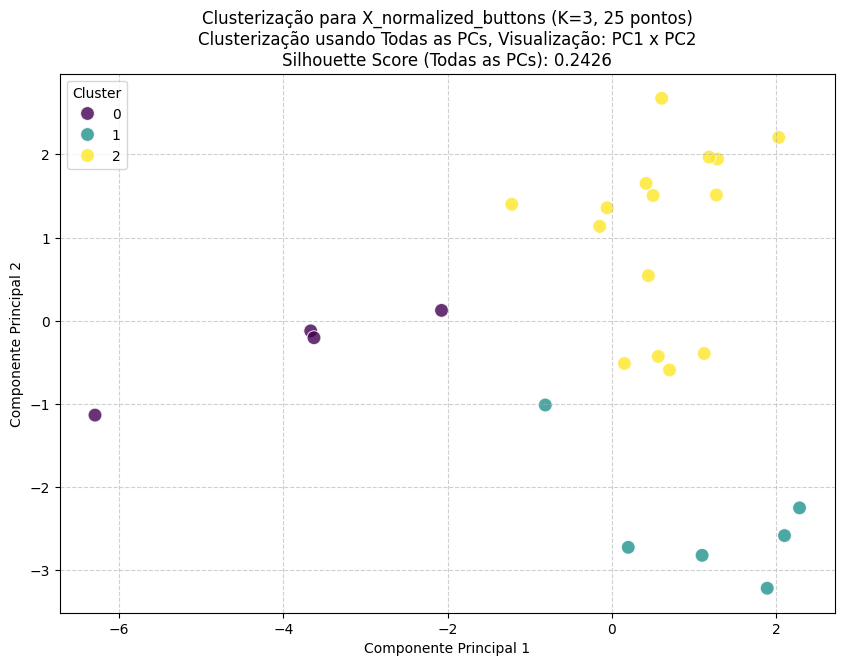


--- Processando dataset: X_normalized_cotton_fabric com K=3 ---
Encontrado NaN no dataset 'X_normalized_cotton_fabric'. Eliminando linhas com NaN...


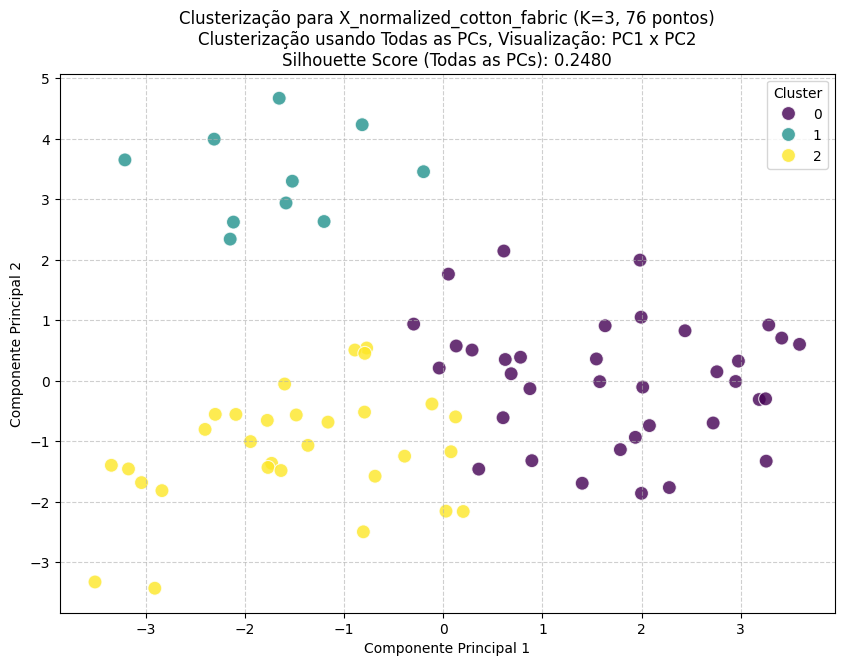


--- Processando dataset: X_normalized_yarn com K=3 ---
Encontrado NaN no dataset 'X_normalized_yarn'. Eliminando linhas com NaN...


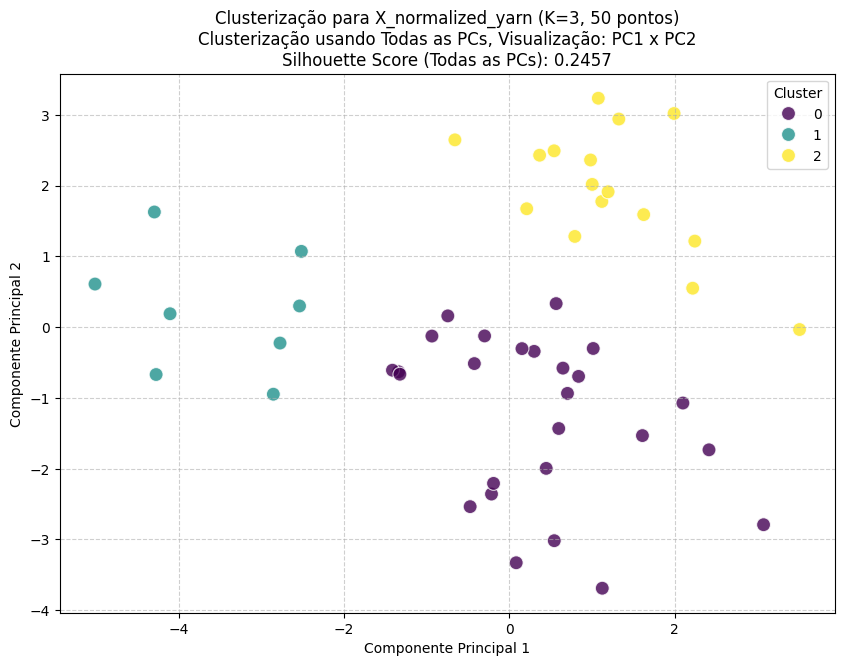


--- Processando dataset: X_normalized_dyes_and_chemicals com K=3 ---
Encontrado NaN no dataset 'X_normalized_dyes_and_chemicals'. Eliminando linhas com NaN...


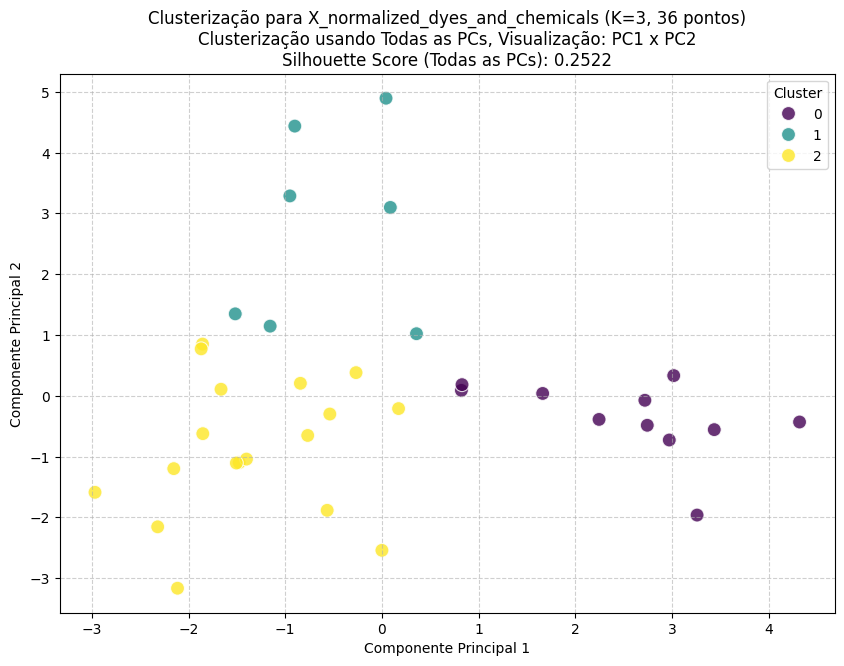


--- Processando dataset: X_normalized_packaging com K=3 ---
Encontrado NaN no dataset 'X_normalized_packaging'. Eliminando linhas com NaN...


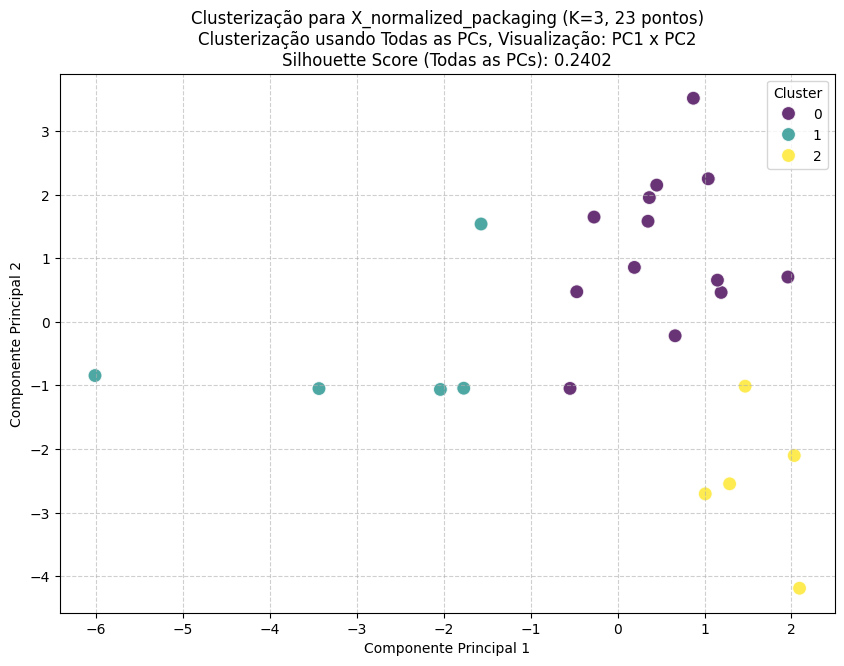


--- Processando dataset: X_normalized_elastic_and_trims com K=3 ---


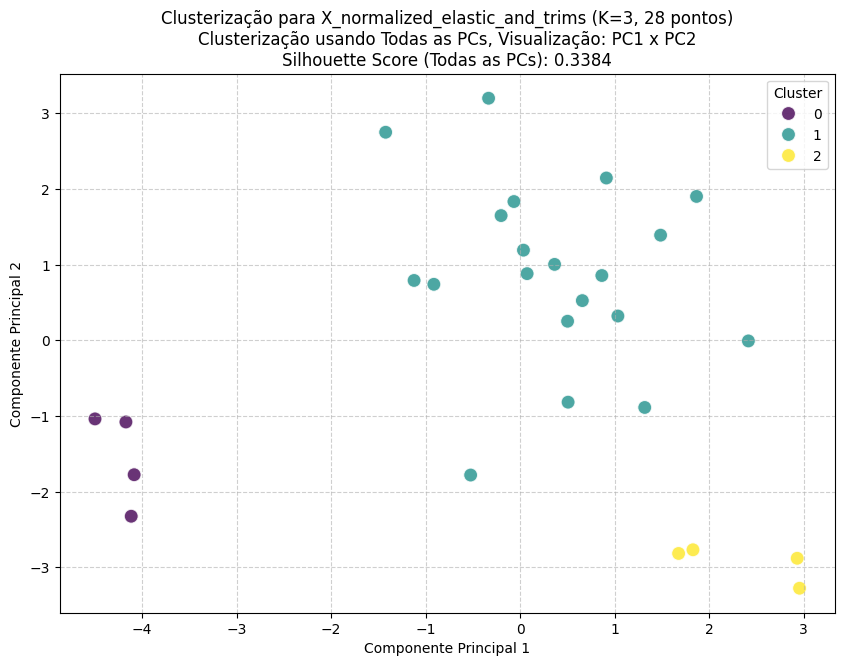


--- Processando dataset: X_normalized_polyester_fabric com K=3 ---
Encontrado NaN no dataset 'X_normalized_polyester_fabric'. Eliminando linhas com NaN...


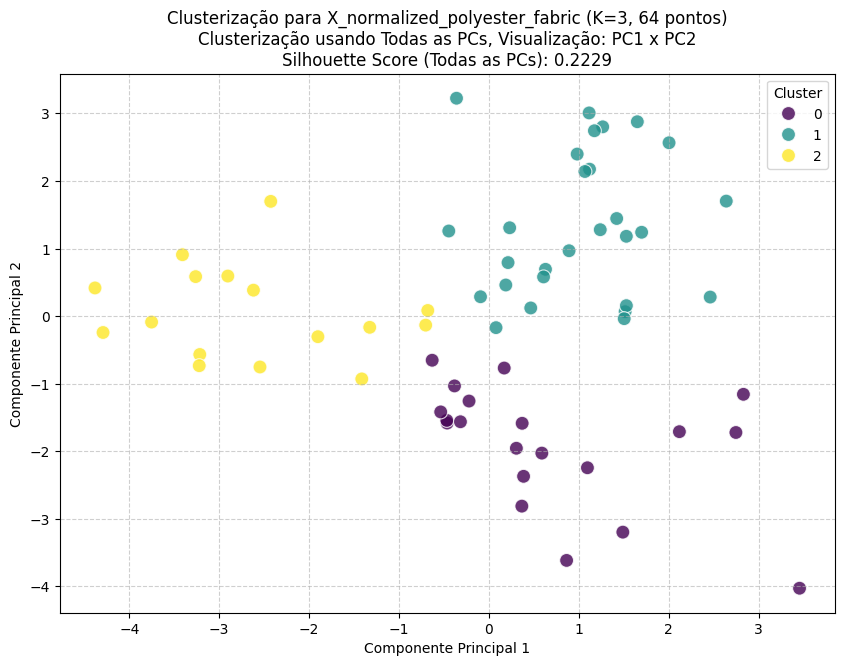


--- Processando dataset: X_normalized_labels_and_tags com K=3 ---
Encontrado NaN no dataset 'X_normalized_labels_and_tags'. Eliminando linhas com NaN...


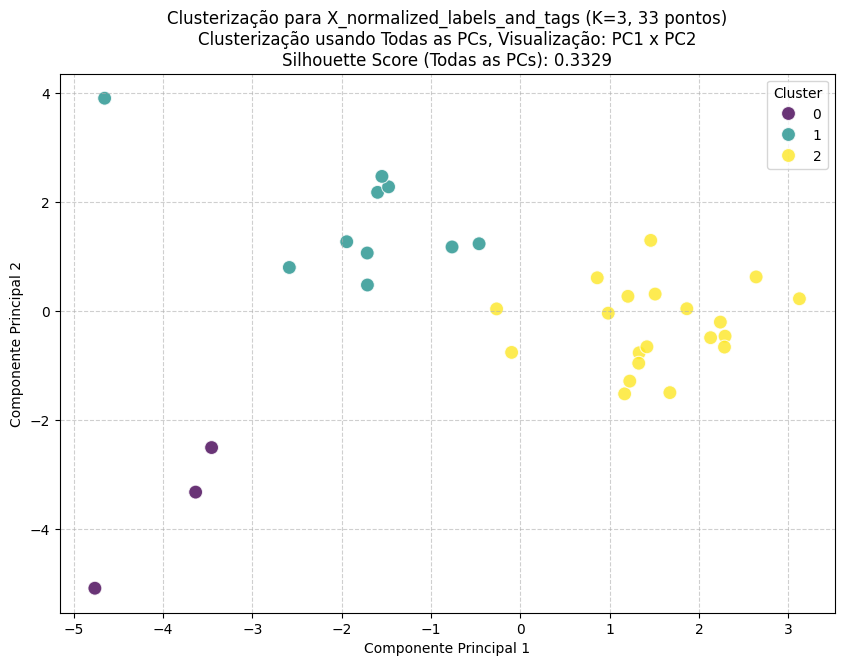


--- Processando dataset: X_normalized_zippers com K=3 ---
Encontrado NaN no dataset 'X_normalized_zippers'. Eliminando linhas com NaN...


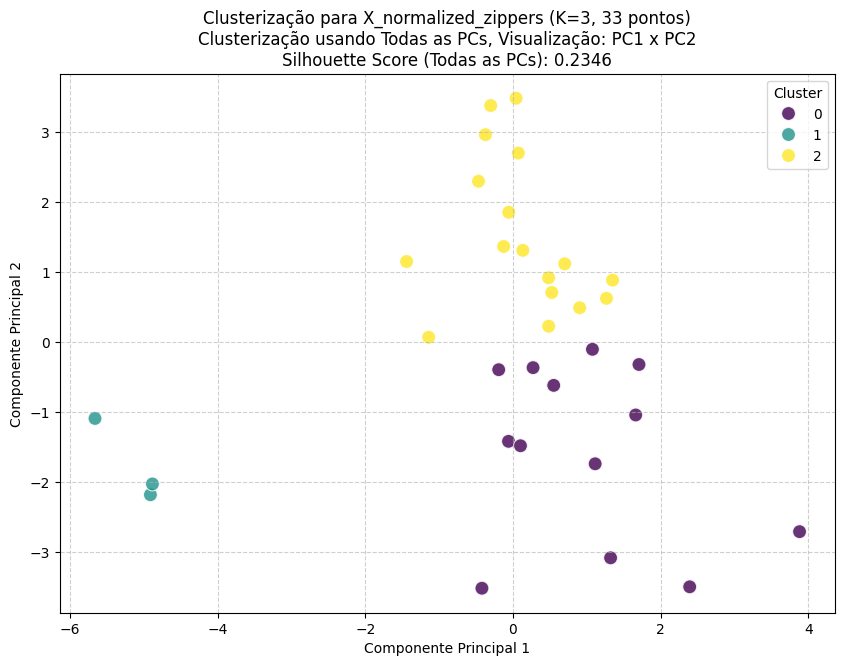


--- Processando dataset: X_normalized_denim com K=3 ---
Encontrado NaN no dataset 'X_normalized_denim'. Eliminando linhas com NaN...


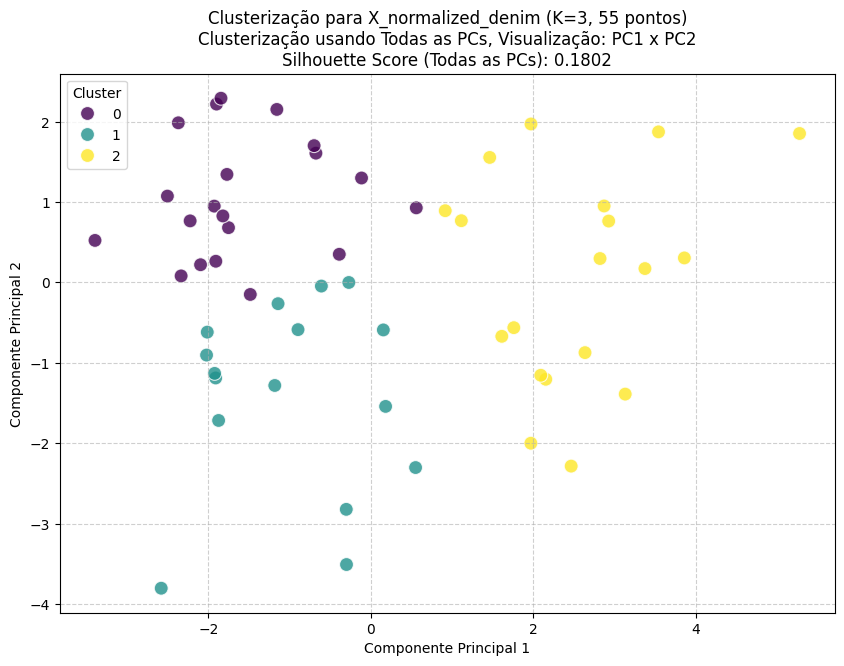


--- Processando dataset: X_normalized_thread com K=3 ---
Encontrado NaN no dataset 'X_normalized_thread'. Eliminando linhas com NaN...


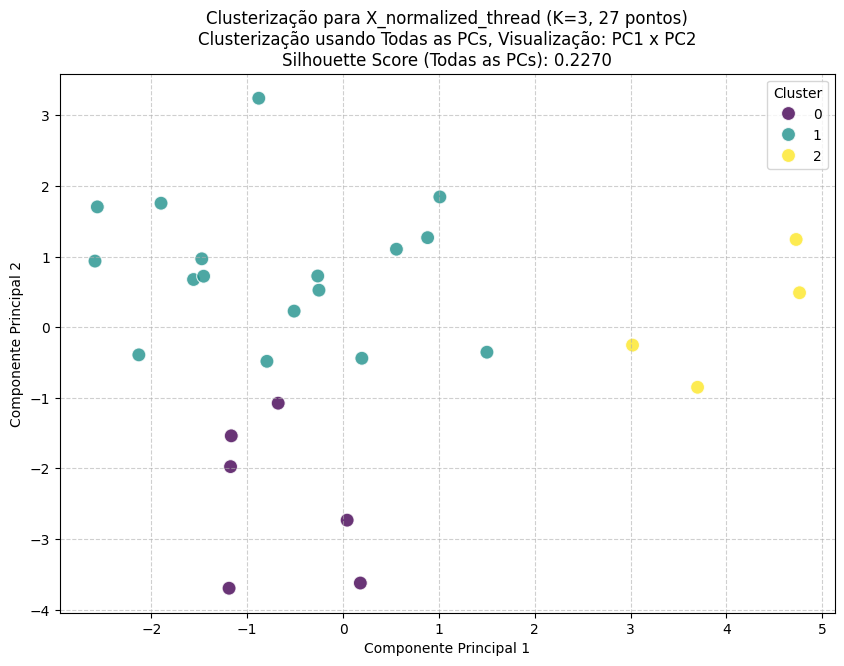

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Importar numpy para verificar NaNs
import pandas as pd # Garantir que pandas esteja importado para operações com DataFrame

k = 3 # Definindo K fixo em 3, conforme o contexto desta célula

# Itera sobre cada sub-dataset normalizado
for dataset_name, X_normalized_sub in normalized_datasets.items():
    print(f"\n--- Processando dataset: {dataset_name} com K={k} ---")

    # Verificar se o dataset não está vazio e tem amostras suficientes
    if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
        print(f"Aviso: Dataset '{dataset_name}' é muito pequeno ou vazio para PCA/Clusterização com K={k}. Pulando...")
        continue

    # === TRATAMENTO DE NaNs ===
    # Verificar se há NaNs e eliminá-los, se necessário
    if X_normalized_sub.isnull().sum().sum() > 0:
        print(f"Encontrado NaN no dataset '{dataset_name}'. Eliminando linhas com NaN...")
        X_normalized_sub = X_normalized_sub.dropna()
        # Após dropar, verificar novamente se o dataset ainda é válido para PCA/Clusterização
        if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
            print(f"Aviso: Após eliminar NaNs, o dataset '{dataset_name}' ficou muito pequeno ou vazio. Pulando...")
            continue
    # === FIM TRATAMENTO DE NaNs ===

    # Aplicar PCA para TODAS as componentes principais para a clusterização
    # n_components=None utiliza todas as componentes, até min(n_samples, n_features) - 1
    pca_full = PCA(n_components=None) # Usar todas as componentes para a clusterização
    X_pca_all_components = pca_full.fit_transform(X_normalized_sub)

    # K-Means Clustering usando TODAS as componentes principais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_sub = kmeans.fit_predict(X_pca_all_components) # Clusterizar usando todas as PCs

    # Calcular Silhouette Score usando TODAS as componentes principais
    if len(set(clusters_sub)) > 1 and X_pca_all_components.shape[0] > k:
        current_silhouette_score = silhouette_score(X_pca_all_components, clusters_sub)
        silhouette_str = f"Silhouette Score (Todas as PCs): {current_silhouette_score:.4f}"
    else:
        silhouette_str = "Silhouette Score: N/A (Não foi possível calcular ou apenas 1 cluster formado)"

    # Para visualização, usar apenas as duas primeiras componentes principais
    n_components_for_plot = min(2, X_pca_all_components.shape[1])
    if n_components_for_plot < 2:
        print(f"Aviso: Dataset '{dataset_name}' tem menos de 2 componentes para plotar. Pulando plotagem...")
        continue # Pula a plotagem, mas a clusterização já foi feita

    df_pca_plot = pd.DataFrame(
        X_pca_all_components[:, :n_components_for_plot], # Selecionar apenas as duas primeiras componentes para o plot
        columns=[f'PC{i+1}' for i in range(n_components_for_plot)],
        index=X_normalized_sub.index
    )

    # Adicionar os clusters ao DataFrame PCA para visualização
    df_pca_plot['Cluster'] = clusters_sub

    # Obter o número de pontos após o tratamento de NaNs
    num_points = df_pca_plot.shape[0]

    # Plotar os resultados
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=df_pca_plot['PC1'], # Primeira Componente Principal para visualização
        y=df_pca_plot['PC2'], # Segunda Componente Principal para visualização
        hue=df_pca_plot['Cluster'], # Colorir por cluster
        palette='viridis',
        s=100,
        alpha=0.8,
        edgecolor='w'
    )

    plt.title(f'Clusterização para {dataset_name} (K={k}, {num_points} pontos)\nClusterização usando Todas as PCs, Visualização: PC1 x PC2\n{silhouette_str}')
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **K=4**


--- Processando dataset: X_normalized_buttons com K=4 ---


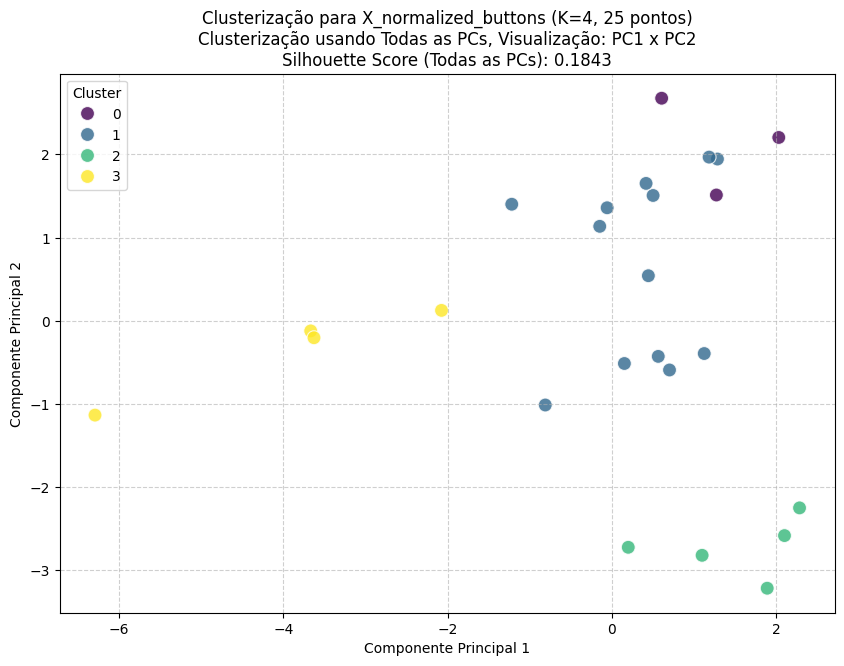


--- Processando dataset: X_normalized_cotton_fabric com K=4 ---
Encontrado NaN no dataset 'X_normalized_cotton_fabric'. Eliminando linhas com NaN...


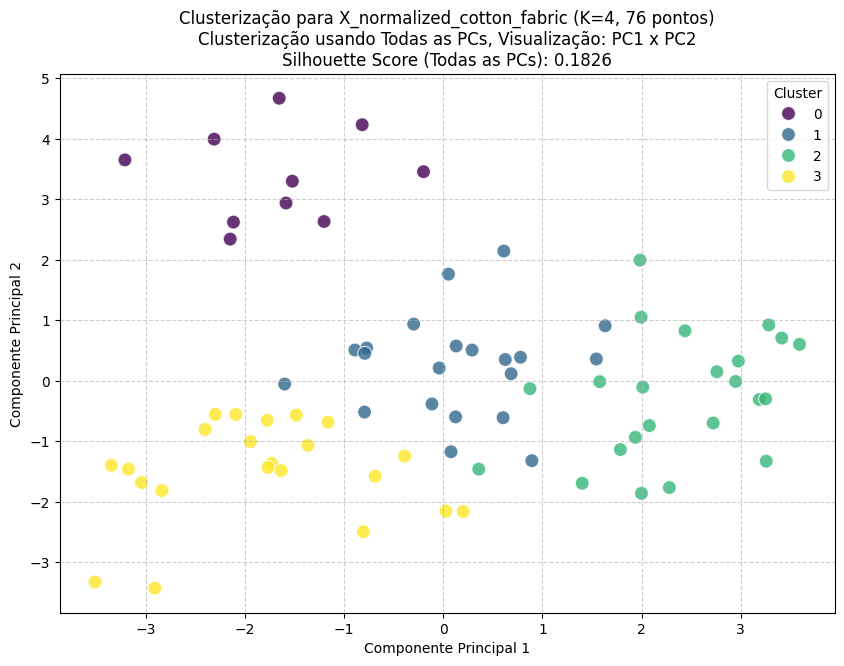


--- Processando dataset: X_normalized_yarn com K=4 ---
Encontrado NaN no dataset 'X_normalized_yarn'. Eliminando linhas com NaN...


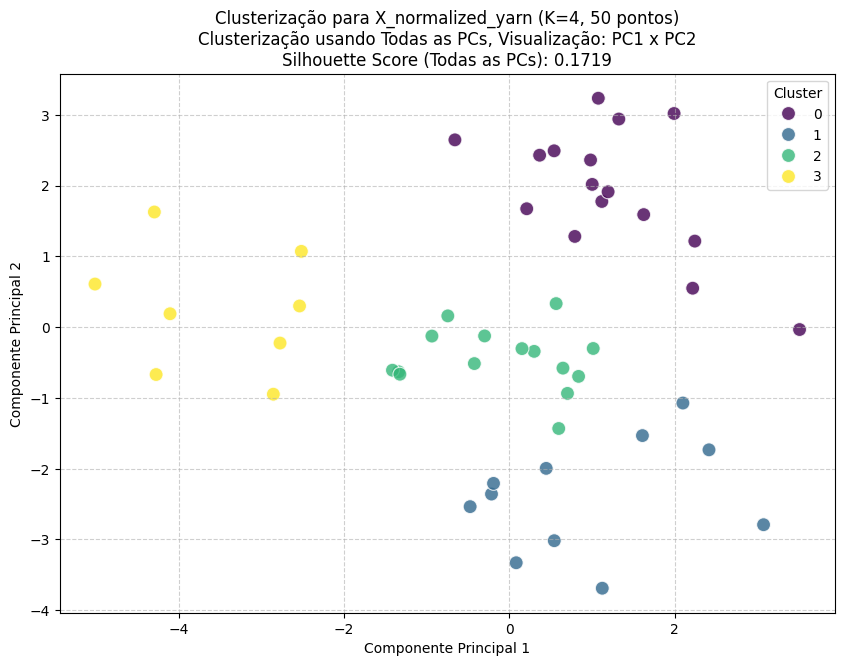


--- Processando dataset: X_normalized_dyes_and_chemicals com K=4 ---
Encontrado NaN no dataset 'X_normalized_dyes_and_chemicals'. Eliminando linhas com NaN...


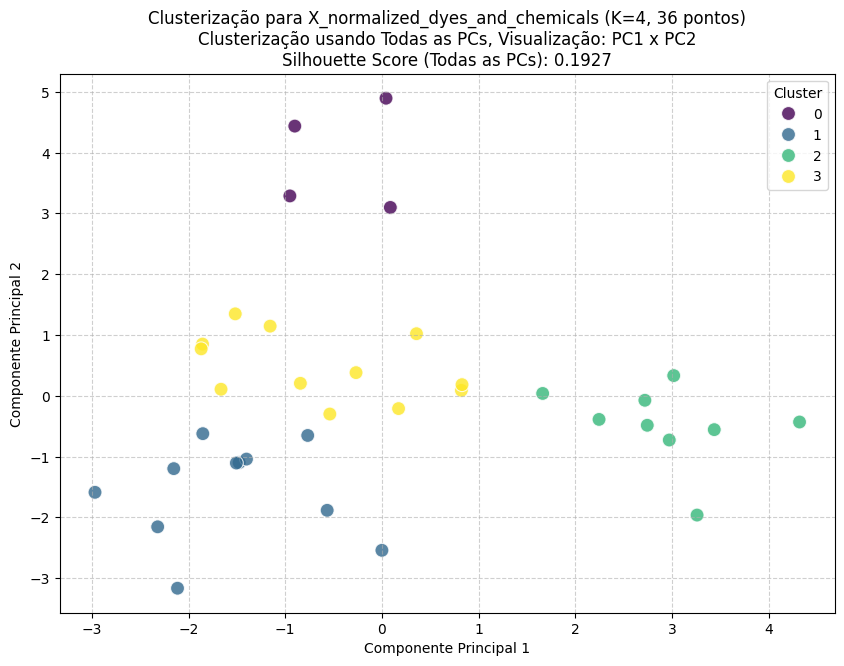


--- Processando dataset: X_normalized_packaging com K=4 ---
Encontrado NaN no dataset 'X_normalized_packaging'. Eliminando linhas com NaN...


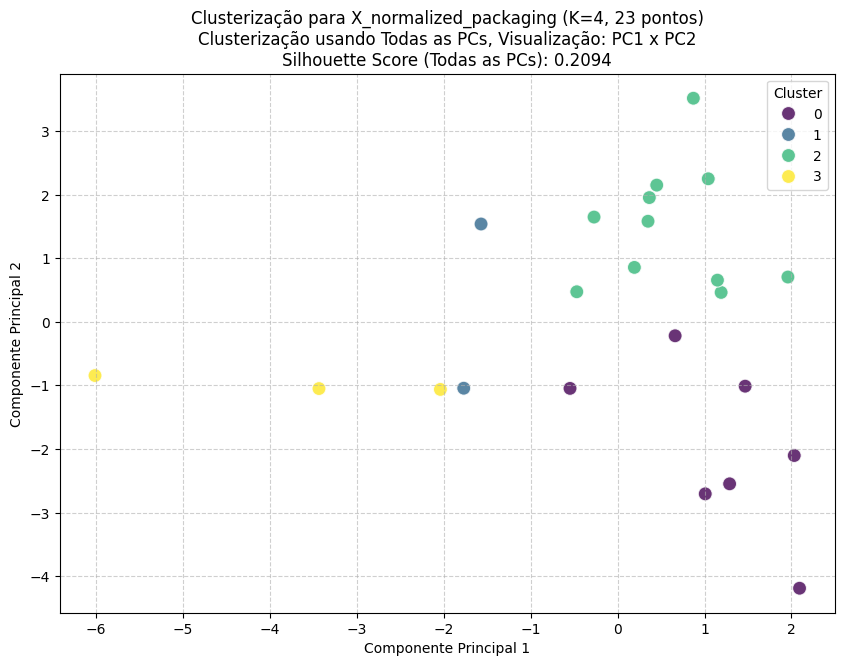


--- Processando dataset: X_normalized_elastic_and_trims com K=4 ---


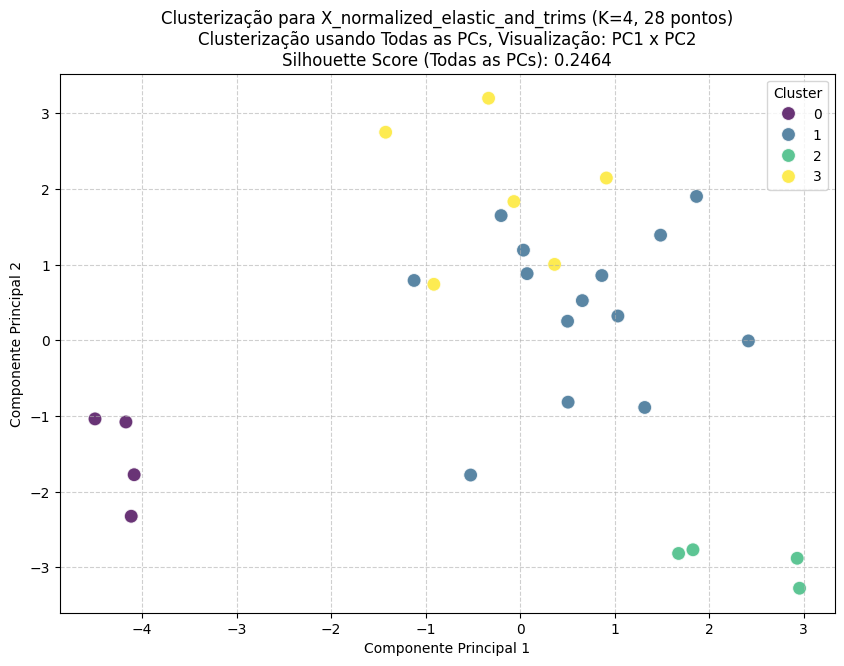


--- Processando dataset: X_normalized_polyester_fabric com K=4 ---
Encontrado NaN no dataset 'X_normalized_polyester_fabric'. Eliminando linhas com NaN...


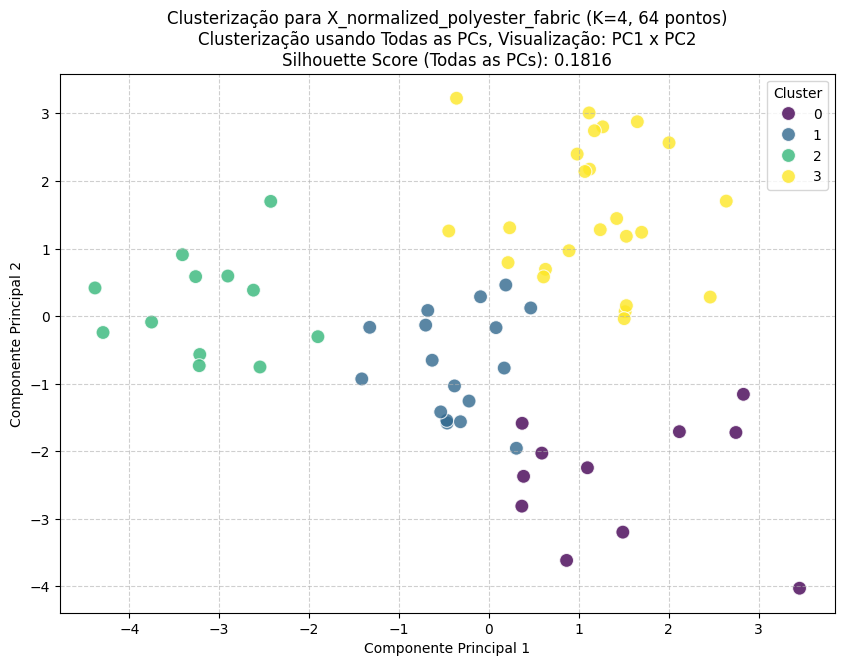


--- Processando dataset: X_normalized_labels_and_tags com K=4 ---
Encontrado NaN no dataset 'X_normalized_labels_and_tags'. Eliminando linhas com NaN...


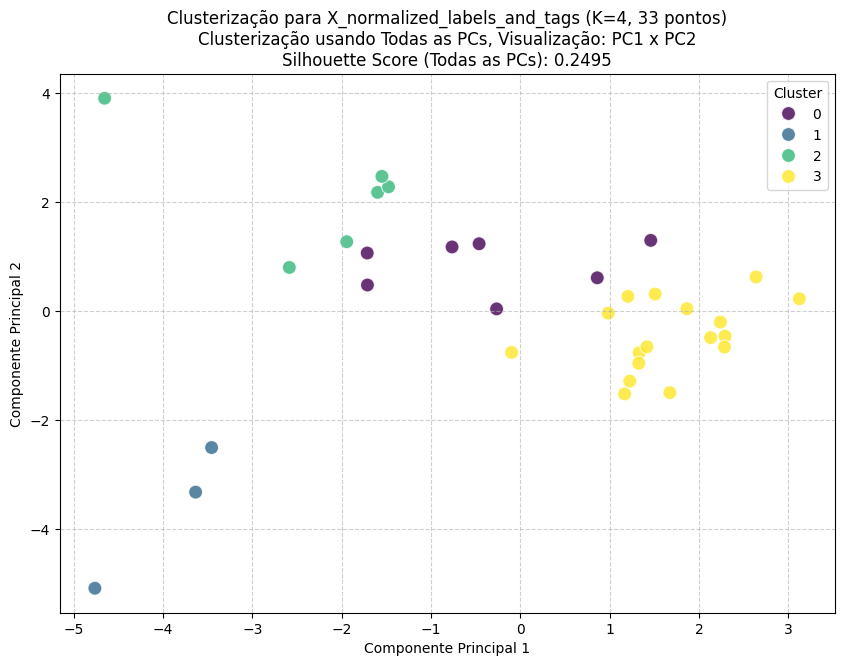


--- Processando dataset: X_normalized_zippers com K=4 ---
Encontrado NaN no dataset 'X_normalized_zippers'. Eliminando linhas com NaN...


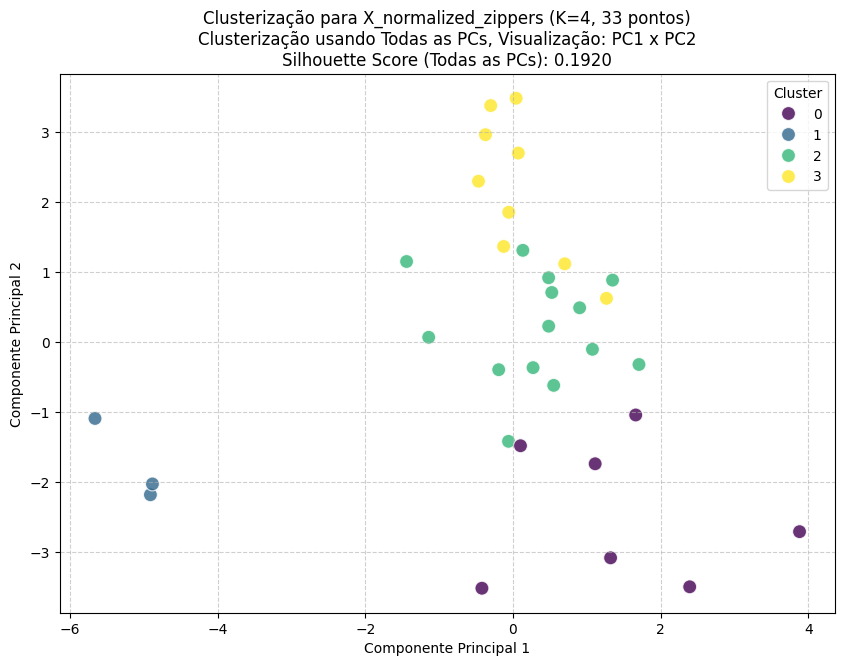


--- Processando dataset: X_normalized_denim com K=4 ---
Encontrado NaN no dataset 'X_normalized_denim'. Eliminando linhas com NaN...


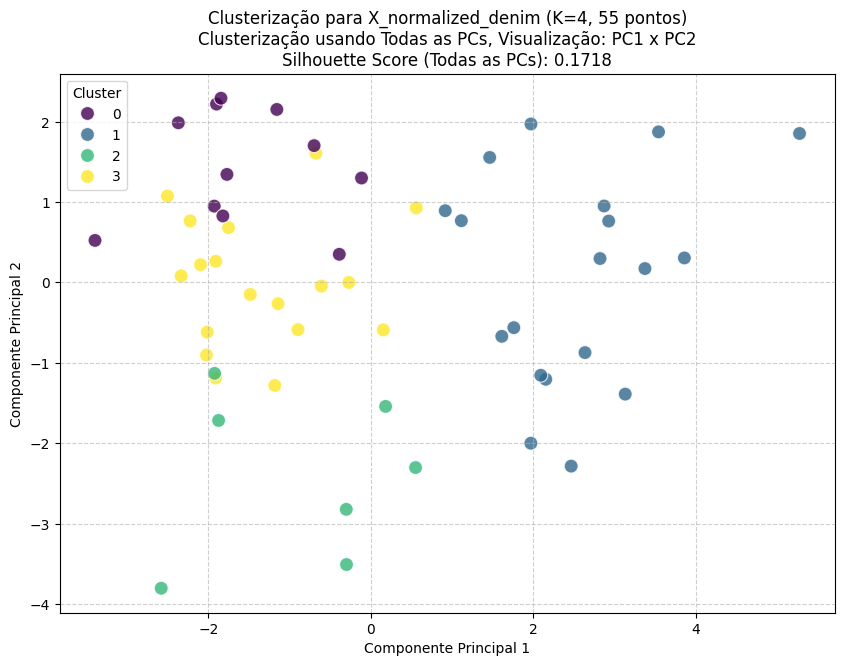


--- Processando dataset: X_normalized_thread com K=4 ---
Encontrado NaN no dataset 'X_normalized_thread'. Eliminando linhas com NaN...


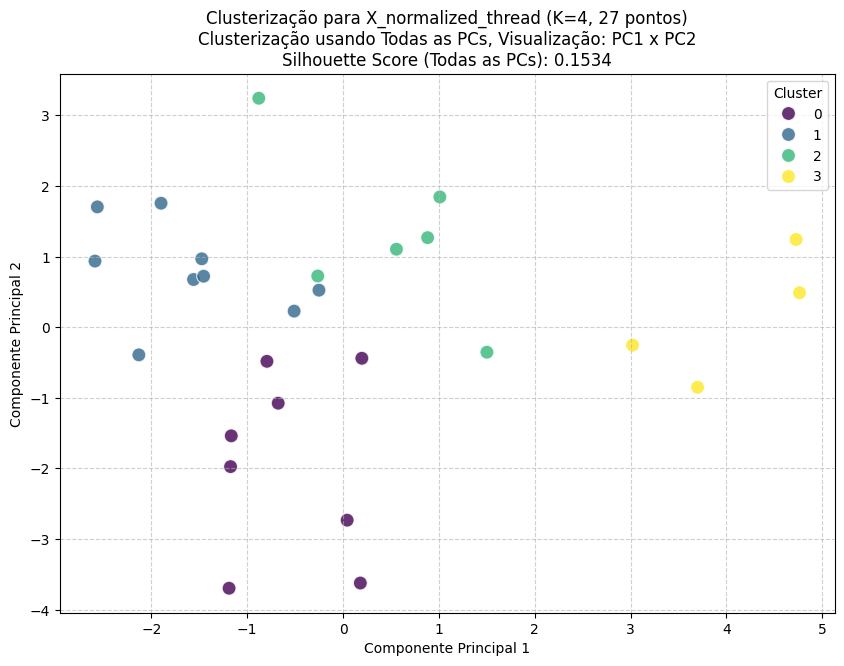

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Importar numpy para verificar NaNs
import pandas as pd # Garantir que pandas esteja importado para operações com DataFrame

k = 4 # Definindo K fixo em 4, conforme o contexto desta célula

# Itera sobre cada sub-dataset normalizado
for dataset_name, X_normalized_sub in normalized_datasets.items():
    print(f"\n--- Processando dataset: {dataset_name} com K={k} ---")

    # Verificar se o dataset não está vazio e tem amostras suficientes
    if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
        print(f"Aviso: Dataset '{dataset_name}' é muito pequeno ou vazio para PCA/Clusterização com K={k}. Pulando...")
        continue

    # === TRATAMENTO DE NaNs ===
    # Verificar se há NaNs e eliminá-los, se necessário
    if X_normalized_sub.isnull().sum().sum() > 0:
        print(f"Encontrado NaN no dataset '{dataset_name}'. Eliminando linhas com NaN...")
        X_normalized_sub = X_normalized_sub.dropna()
        # Após dropar, verificar novamente se o dataset ainda é válido para PCA/Clusterização
        if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
            print(f"Aviso: Após eliminar NaNs, o dataset '{dataset_name}' ficou muito pequeno ou vazio. Pulando...")
            continue
    # === FIM TRATAMENTO DE NaNs ===

    # Aplicar PCA para TODAS as componentes principais para a clusterização
    # n_components=None utiliza todas as componentes, até min(n_samples, n_features) - 1
    pca_full = PCA(n_components=None) # Usar todas as componentes para a clusterização
    X_pca_all_components = pca_full.fit_transform(X_normalized_sub)

    # K-Means Clustering usando TODAS as componentes principais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_sub = kmeans.fit_predict(X_pca_all_components) # Clusterizar usando todas as PCs

    # Calcular Silhouette Score usando TODAS as componentes principais
    if len(set(clusters_sub)) > 1 and X_pca_all_components.shape[0] > k:
        current_silhouette_score = silhouette_score(X_pca_all_components, clusters_sub)
        silhouette_str = f"Silhouette Score (Todas as PCs): {current_silhouette_score:.4f}"
    else:
        silhouette_str = "Silhouette Score: N/A (Não foi possível calcular ou apenas 1 cluster formado)"

    # Para visualização, usar apenas as duas primeiras componentes principais
    n_components_for_plot = min(2, X_pca_all_components.shape[1])
    if n_components_for_plot < 2:
        print(f"Aviso: Dataset '{dataset_name}' tem menos de 2 componentes para plotar. Pulando plotagem...")
        continue # Pula a plotagem, mas a clusterização já foi feita

    df_pca_plot = pd.DataFrame(
        X_pca_all_components[:, :n_components_for_plot], # Selecionar apenas as duas primeiras componentes para o plot
        columns=[f'PC{i+1}' for i in range(n_components_for_plot)],
        index=X_normalized_sub.index
    )

    # Adicionar os clusters ao DataFrame PCA para visualização
    df_pca_plot['Cluster'] = clusters_sub

    # Obter o número de pontos após o tratamento de NaNs
    num_points = df_pca_plot.shape[0]

    # Plotar os resultados
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=df_pca_plot['PC1'], # Primeira Componente Principal para visualização
        y=df_pca_plot['PC2'], # Segunda Componente Principal para visualização
        hue=df_pca_plot['Cluster'], # Colorir por cluster
        palette='viridis',
        s=100,
        alpha=0.8,
        edgecolor='w'
    )

    plt.title(f'Clusterização para {dataset_name} (K={k}, {num_points} pontos)\nClusterização usando Todas as PCs, Visualização: PC1 x PC2\n{silhouette_str}')
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **Resultados:**

Para cada produto, ao aplicar PCA, os melhores números de clusters seriam:

Buttons: K=3

Cotton Fabric: K=3

Denim: K=2

Dyes and Chemicals: K=3

Elastic and Trims: K=2

Labels and Tags: K=3

Packaging: K=2

Polyster Fabric: K=3

Thread: K=2

Yarn: K=2

Zippers: K=2

# **Conclusões e matriz de portifólio:**

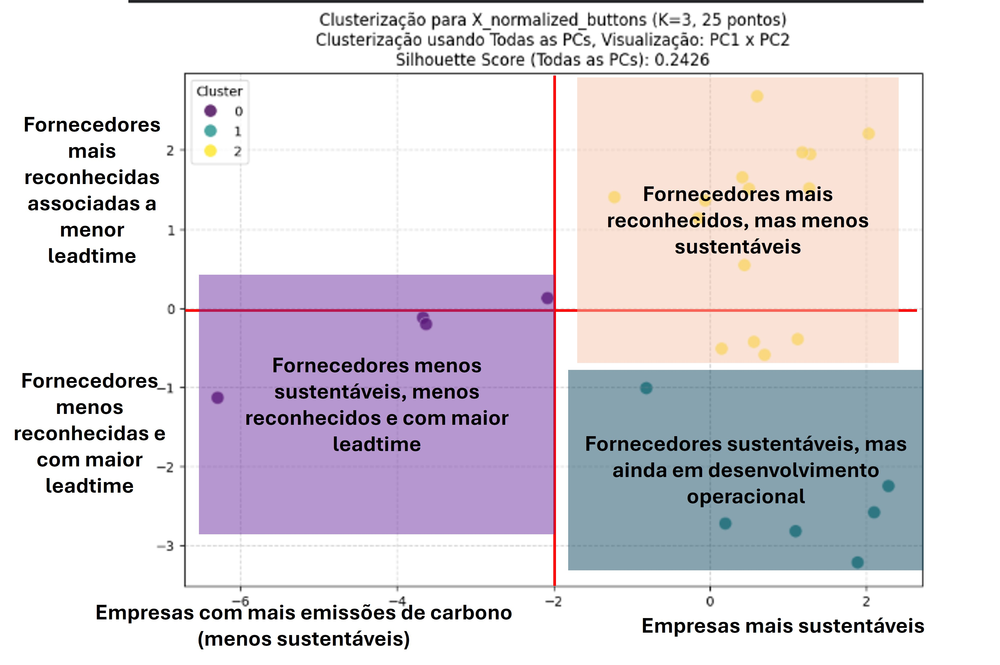

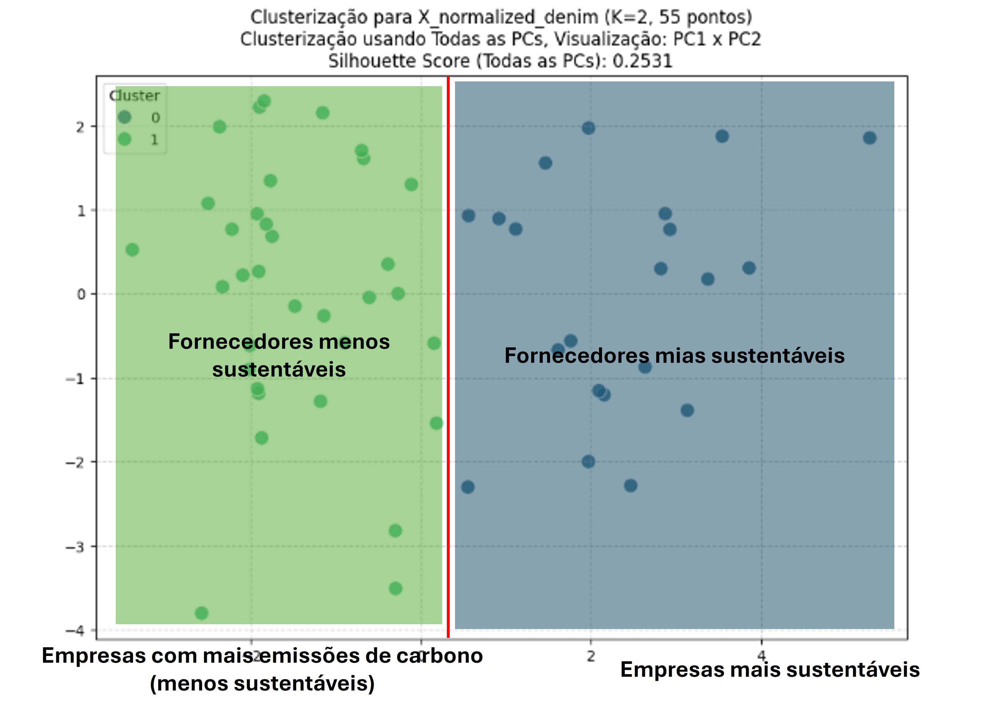

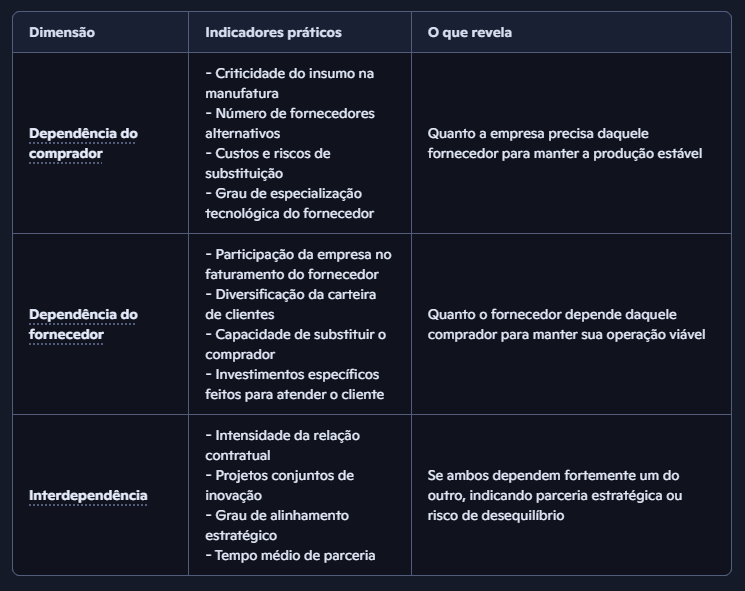

# **Tirando as variáveis de Avg Rating e N awards:**

In [ ]:
# Como o Perfomance Band é uma variável qualitativa, esta parte do código lê os dados de fornecedores, filtra apenas algumas categorias de desempenho, remove valores faltantes (linhas vazias) e seleciona variáveis importantes. Em seguida, normaliza esses dados

from sklearn.preprocessing import StandardScaler

suppliers_df = pd.read_excel("/content/supplier_recommender_textile (1).xlsx", sheet_name="SUPPLIERS")
plot_order = ['POOR', 'AVERAGE', 'GOOD']
suppliers_df_cleaned = suppliers_df[suppliers_df['performance_band'].isin(plot_order)]
predictors_quanti_semvariaveis = [
    "price_index_vs_market",       # F=178
    "sustainability_score",        # F=92
    "defect_rate_pct",             # F=89
    "relationship_years",          # F=71
    "monthly_capacity_units",      # F=69
    "on_time_delivery_pct",        # F=68
    "financial_risk_prob_default", # F robusto
    "co2_kg_per_unit",
    "n_events",
    "avg_lead_time_days",
]

df_clean = suppliers_df_cleaned.dropna(subset=predictors_quanti_semvariaveis + ['performance_band']).copy()

X = df_clean[predictors_quanti_semvariaveis]
X_normalized_semvariaveis = StandardScaler().fit_transform(X)


print("Célula 1: Dados normalizados.")

print(f"Total de fornecedores na análise: {len(suppliers_df_cleaned)}")
print(f"Bandas de performance a serem analisadas: {plot_order}")

Célula 1: Dados normalizados.
Total de fornecedores na análise: 460
Bandas de performance a serem analisadas: ['POOR', 'AVERAGE', 'GOOD']


In [ ]:
X_normalized_semvariaveis

array([[-0.30885239, -1.99278593,  2.75745256, ...,  2.10383579,
        -1.23899893,  0.55997224],
       [ 0.38324444,  0.08364125,  0.03248148, ..., -0.30182295,
        -0.93437358, -0.70737619],
       [-0.39536449,  0.63328374, -1.05040605, ..., -0.59422346,
        -0.71678406,  1.0412438 ],
       ...,
       [-0.6549008 , -1.87064316,  0.94672259, ...,  1.1402432 ,
        -1.45658845,  0.81665041],
       [ 0.29673234,  0.75542651,  0.28101304, ...,  0.49563299,
        -0.80381987, -0.72341857],
       [-0.74141291,  0.45006957, -0.22492621, ...,  1.53232571,
         1.93780819, -1.15656297]])


Variância Explicada:
  Componente  Variancia_Explicada  Variancia_Acumulada
0        PC1             0.319278             0.319278
1        PC2             0.167901             0.487179
2        PC3             0.101224             0.588403
3        PC4             0.079979             0.668382
4        PC5             0.072782             0.741164
5        PC6             0.063687             0.804851
6        PC7             0.056155             0.861006
7        PC8             0.050360             0.911366
8        PC9             0.046599             0.957965
9       PC10             0.042035             1.000000


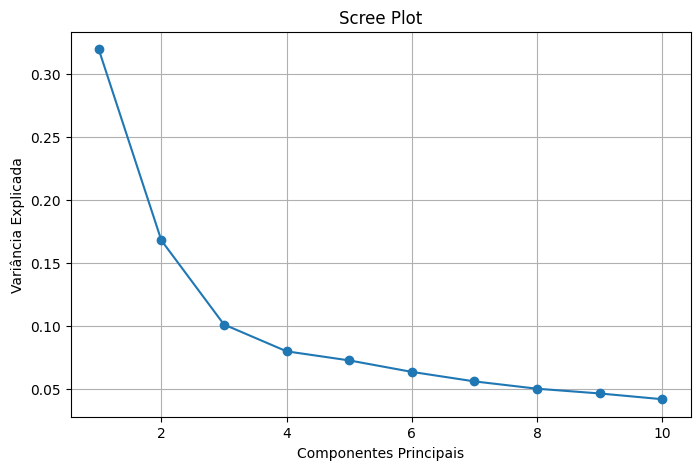

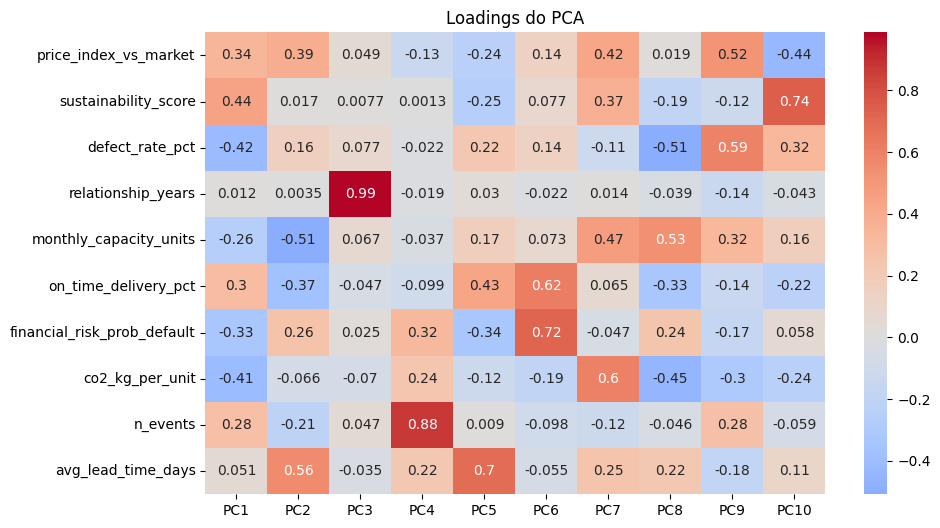

In [ ]:
# =========================
# SELEÇÃO DAS FEATURES
# =========================

# Using 'predictors_quanti_semvariaveis' from the existing notebook context
# This now reflects the features used to create X_normalized_semvariaveis
features = predictors_quanti_semvariaveis

# The data X_normalized_semvariaveis is already standardized from previous steps.
X_scaled = X_normalized_semvariaveis

# =========================
# PCA
# =========================

pca = PCA() # Initialize PCA without specifying n_components to get all components

X_pca = pca.fit_transform(X_scaled)

# =========================
# VARIÂNCIA EXPLICADA
# =========================

explained_variance = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(len(features))],
    'Variancia_Explicada': pca.explained_variance_ratio_,
    'Variancia_Acumulada': np.cumsum(pca.explained_variance_ratio_)
})

print("\nVariância Explicada:")
print(explained_variance)

# =========================
# LOADINGS
# =========================

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(features))],
    index=features
)

#print("\nLoadings:")
#print(loadings)

# =========================
# CONTRIBUIÇÃO ABSOLUTA
# =========================

contribuicao = loadings.abs()

#print("\nContribuição Absoluta:")
#print(contribuicao)

# =========================
# TOP FEATURES POR COMPONENTE
# =========================

for pc in loadings.columns:
    #print(f"\nTop features - {pc}")

    top = contribuicao[pc].sort_values(ascending=False)

    #print(top)

# =========================
# SCREE PLOT
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(features)+1),
    pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel('Componentes Principais')
plt.ylabel('Variância Explicada')
plt.title('Scree Plot')

plt.grid(True)
plt.show()

# =========================
# HEATMAP DOS LOADINGS
# =========================

plt.figure(figsize=(10,6))

sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title('Loadings do PCA')
plt.show()


--- Clusterização com K=3 ---
Silhouette Score para K=3: 0.2009


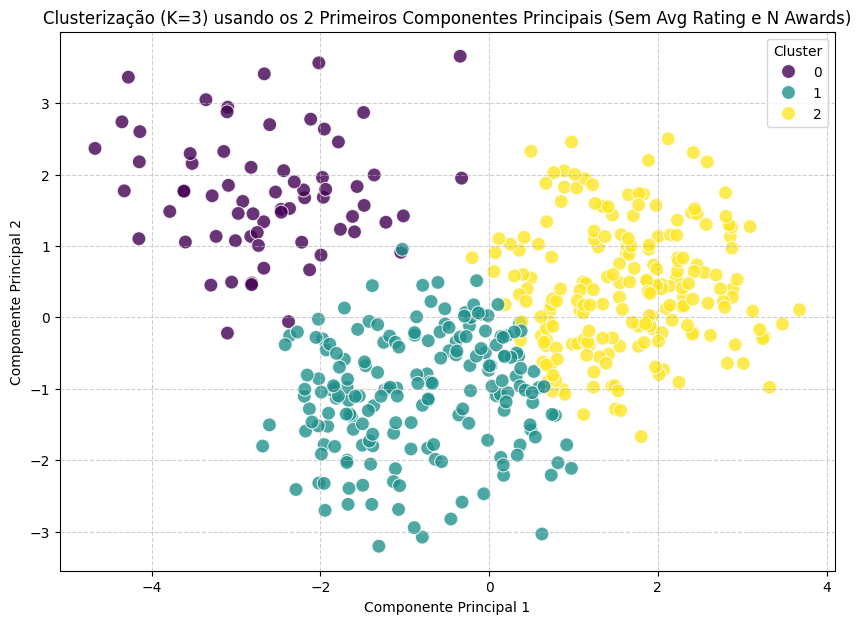

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

k = 3 # Based on previous analysis for optimal K

print(f"\n--- Clusterização com K={k} ---")

# =========================
# K-MEANS CLUSTERING
# =========================

# Usando TODAS as componentes principais (X_pca) para a clusterização
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init to suppress warning
clusters = kmeans.fit_predict(X_pca) # Fit KMeans on ALL PCs

# Calculate Silhouette Score usando TODAS as componentes principais
current_silhouette_score = silhouette_score(X_pca, clusters)
print(f"Silhouette Score para K={k}: {current_silhouette_score:.4f}")

# =========================
# CLUSTERING PLOT
# =========================

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], # First Principal Component (for visualization)
    y=X_pca[:, 1], # Second Principal Component (for visualization)
    hue=clusters,  # Color by assigned cluster
    palette='viridis', # Choose a color palette
    s=100,         # Marker size
    alpha=0.8,     # Transparency
    edgecolor='w'  # White edge around markers
)

plt.title(f'Clusterização (K={k}) usando os 2 Primeiros Componentes Principais (Sem Avg Rating e N Awards)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Cluster')
plt.show()

# Optional: Add cluster labels to the original clean DataFrame for potential further analysis
df_clean['Cluster_K3_PCA_SemVariaveis'] = clusters


--- Clusterização com K=2 ---
Silhouette Score para K=2: 0.2155


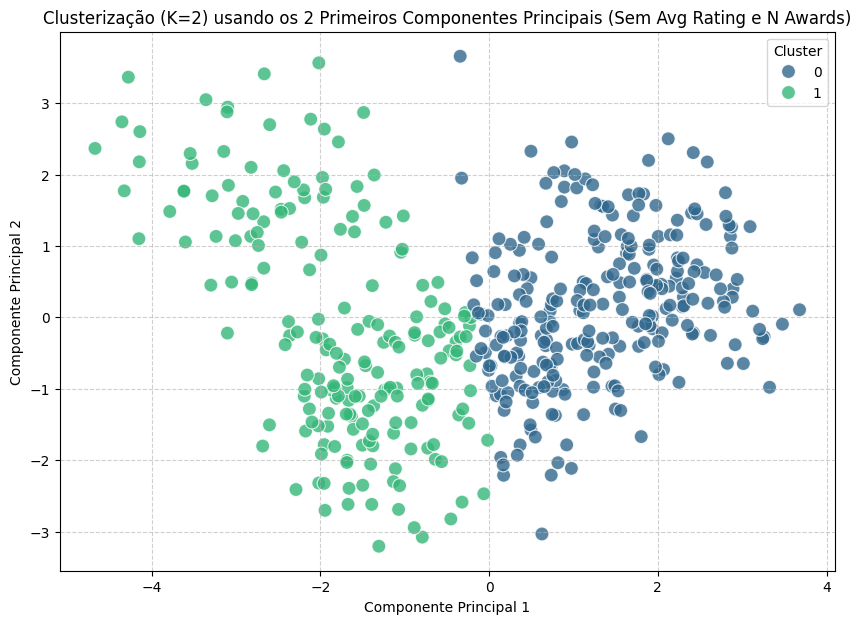


--- Clusterização com K=3 ---
Silhouette Score para K=3: 0.2009


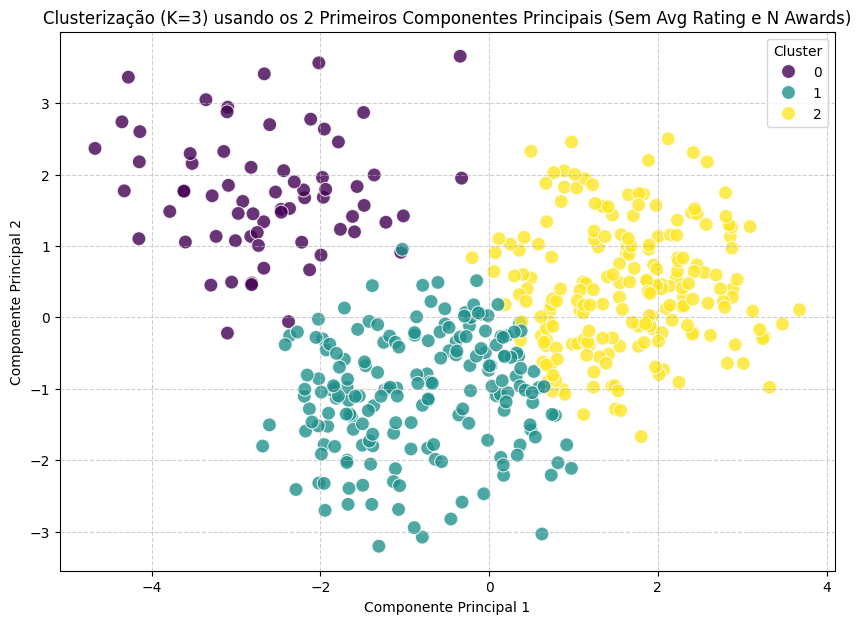


--- Clusterização com K=4 ---
Silhouette Score para K=4: 0.1363


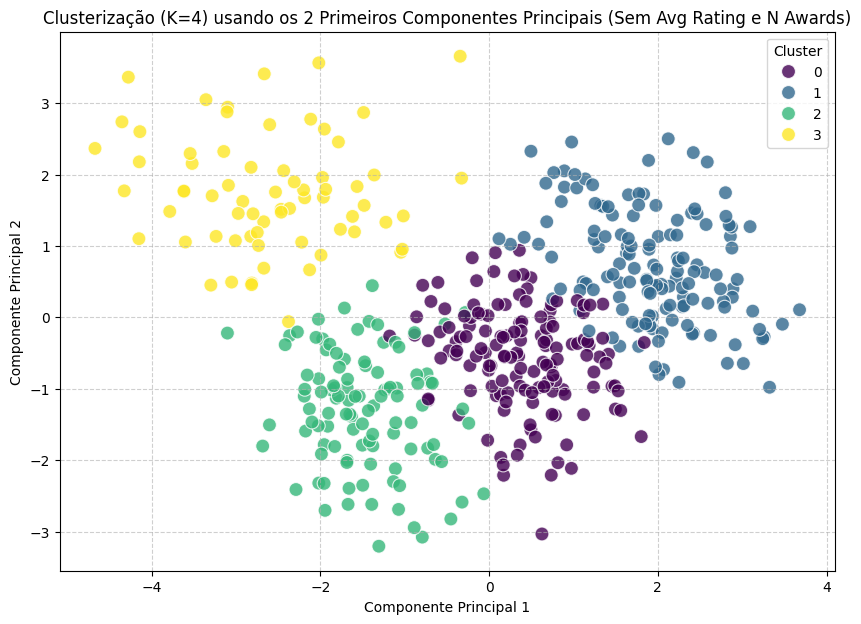

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

k_values = [2, 3, 4]

for k in k_values:
    print(f"\n--- Clusterização com K={k} ---")

    # =========================
    # K-MEANS CLUSTERING
    # =========================

    # Usando TODAS as componentes principais (X_pca) para a clusterização
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init to suppress warning
    clusters = kmeans.fit_predict(X_pca) # Fit KMeans on ALL PCs

    # Calculate Silhouette Score usando TODAS as componentes principais
    current_silhouette_score = silhouette_score(X_pca, clusters)
    print(f"Silhouette Score para K={k}: {current_silhouette_score:.4f}")

    # =========================
    # CLUSTERING PLOT
    # =========================

    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=X_pca[:, 0], # First Principal Component (for visualization)
        y=X_pca[:, 1], # Second Principal Component (for visualization)
        hue=clusters,  # Color by assigned cluster
        palette='viridis', # Choose a color palette
        s=100,         # Marker size
        alpha=0.8,     # Transparency
        edgecolor='w'  # White edge around markers
    )

    plt.title(f'Clusterização (K={k}) usando os 2 Primeiros Componentes Principais (Sem Avg Rating e N Awards)')
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **Separando por produto sem as variaveis Avareg Rating e N awards:**

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Check if an Excel file was uploaded and load it into df
# Corrected filename check based on 'uploaded' variable in kernel state
if 'supplier_recommender_textile (1).xlsx' in uploaded:
    df = pd.read_excel(uploaded['supplier_recommender_textile (1).xlsx'])
    print("DataFrame 'df' loaded successfully from uploaded Excel file.")
elif 'df_clean' in globals(): # Fallback to existing df_clean if df is not loaded and df_clean exists
    df = df_clean.copy()
    print("DataFrame 'df' assigned from 'df_clean'.")
elif 'suppliers_df_cleaned' in globals():
    df = suppliers_df_cleaned.copy()
    print("DataFrame 'df' assigned from 'suppliers_df_cleaned'.")
else:
    print("Error: No suitable DataFrame found to assign to 'df'. Please ensure 'df' or a similar DataFrame is loaded.")
    # Optionally, you might want to exit or raise an exception here if df is critical
    # For this adaptation, we assume df will be assigned by one of the above.

# VARIÁVEIS ESCOLHIDAS (agora usando a lista sem 'avg_rating' e 'n_awards')
features = predictors_quanti_semvariaveis

# DICIONÁRIO PARA SALVAR
normalized_datasets = {}

# Handle 'product_focus' for iteration
if 'product_focus' in df.columns:
    grouping_column = 'product_focus'
    unique_groups = df[grouping_column].unique()
    print(f"Agrupando por '{grouping_column}'. Grupos únicos encontrados: {unique_groups}")
else:
    print("Aviso: Coluna 'product_focus' não encontrada no DataFrame 'df'.")
    print("Prosseguindo sem agrupar por 'product_focus', normalizando o conjunto de dados completo como um único grupo.")
    grouping_column = None # No grouping will occur
    unique_groups = [None] # A single 'group' to iterate once through the entire dataframe

for group_value in unique_groups:
    if grouping_column:
        # Create subbase if grouping_column exists
        subbase = df[df[grouping_column] == group_value].copy()
        # Sanitize product_nome for variable names
        produto_nome = str(group_value).lower().replace(" ", "_").replace("&", "and").replace("/", "_").replace("-", "_")
    else:
        # If no grouping column, process the entire df as a single 'group'
        subbase = df.copy()
        produto_nome = "full_dataset" # Name for the single group

    # Selecionar variáveis
    X = subbase[features]

    # Normalização
    scaler = StandardScaler()

    # Handle cases where X might be empty for a group (e.g., if a group has no data for the features)
    if not X.empty:
        X_normalized = scaler.fit_transform(X)

        # Transformar em DataFrame
        X_normalized = pd.DataFrame(
            X_normalized,
            columns=features,
            index=subbase.index
        )

        # O nome da variável de saída refletirá que ela vem de um sub-dataset normalizado
        nome_variavel = f"X_normalized_{produto_nome}_semvariaveis"

        # Salvar no dicionário
        normalized_datasets[nome_variavel] = X_normalized

        # Criar variável automática no escopo global
        globals()[nome_variavel] = X_normalized

        print(f"{nome_variavel} criado com sucesso!")
    else:
        print(f"Pulando a normalização para o grupo '{group_value}' devido a uma sub-base vazia.")

/tmp/ipykernel_2083/2901871357.py:7: FutureWarning: Passing bytes to 'read_excel' is deprecated and will be removed in a future version. To read from a byte string, wrap it in a `BytesIO` object.
  df = pd.read_excel(uploaded['supplier_recommender_textile (1).xlsx'])


DataFrame 'df' loaded successfully from uploaded Excel file.
Agrupando por 'product_focus'. Grupos únicos encontrados: ['Buttons' 'Cotton Fabric' 'Yarn' 'Dyes & Chemicals' 'Packaging'
 'Elastic & Trims' 'Polyester Fabric' 'Labels & Tags' 'Zippers' 'Denim'
 'Thread']
X_normalized_buttons_semvariaveis criado com sucesso!
X_normalized_cotton_fabric_semvariaveis criado com sucesso!
X_normalized_yarn_semvariaveis criado com sucesso!
X_normalized_dyes_and_chemicals_semvariaveis criado com sucesso!
X_normalized_packaging_semvariaveis criado com sucesso!
X_normalized_elastic_and_trims_semvariaveis criado com sucesso!
X_normalized_polyester_fabric_semvariaveis criado com sucesso!
X_normalized_labels_and_tags_semvariaveis criado com sucesso!
X_normalized_zippers_semvariaveis criado com sucesso!
X_normalized_denim_semvariaveis criado com sucesso!
X_normalized_thread_semvariaveis criado com sucesso!


# **K=2**


--- Processando dataset: X_normalized_buttons_semvariaveis com K=2 ---


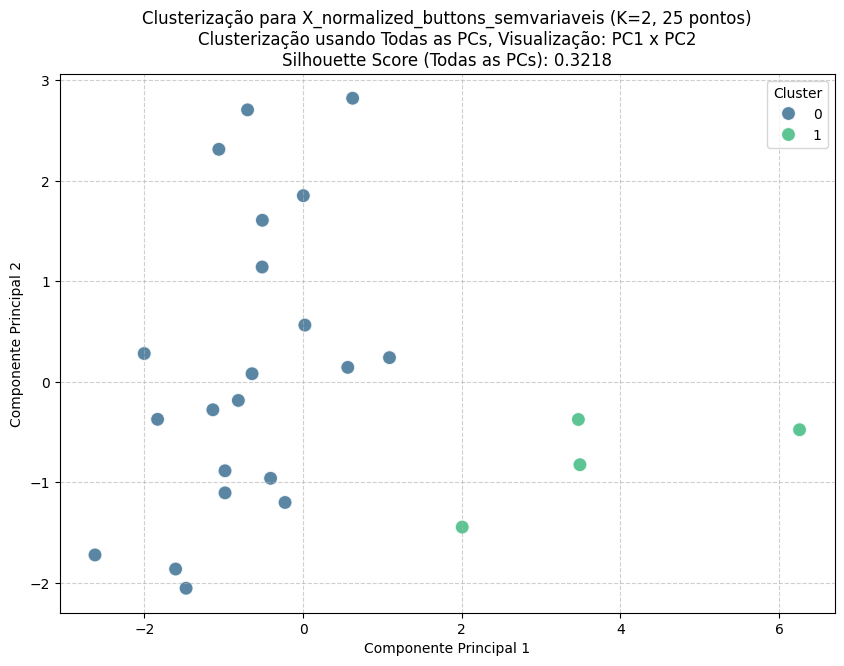


--- Processando dataset: X_normalized_cotton_fabric_semvariaveis com K=2 ---


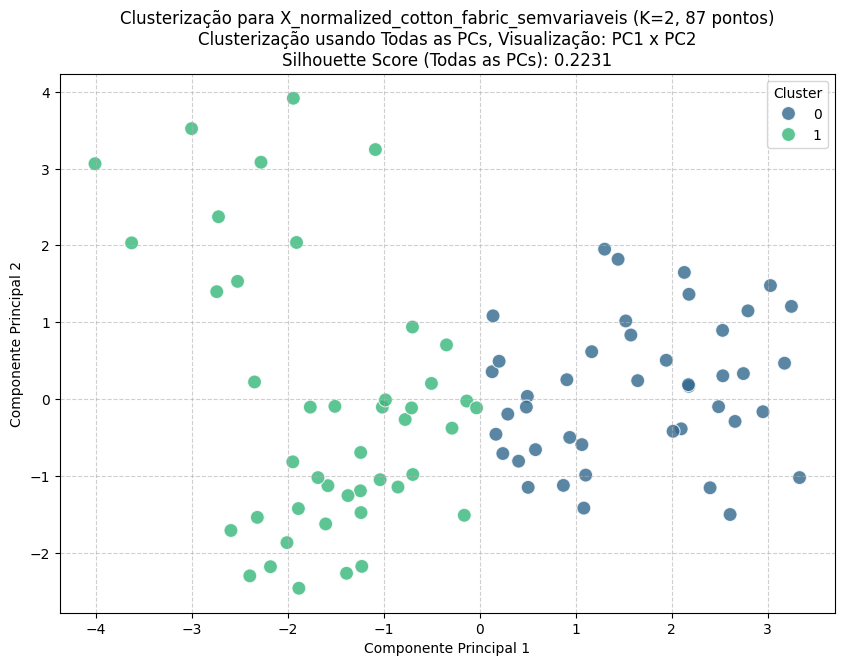


--- Processando dataset: X_normalized_yarn_semvariaveis com K=2 ---


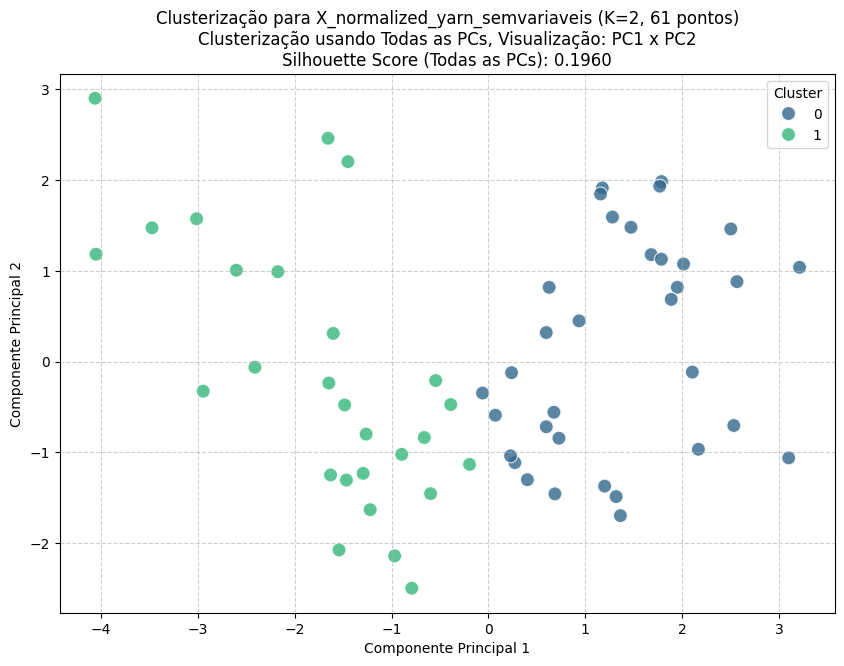


--- Processando dataset: X_normalized_dyes_and_chemicals_semvariaveis com K=2 ---


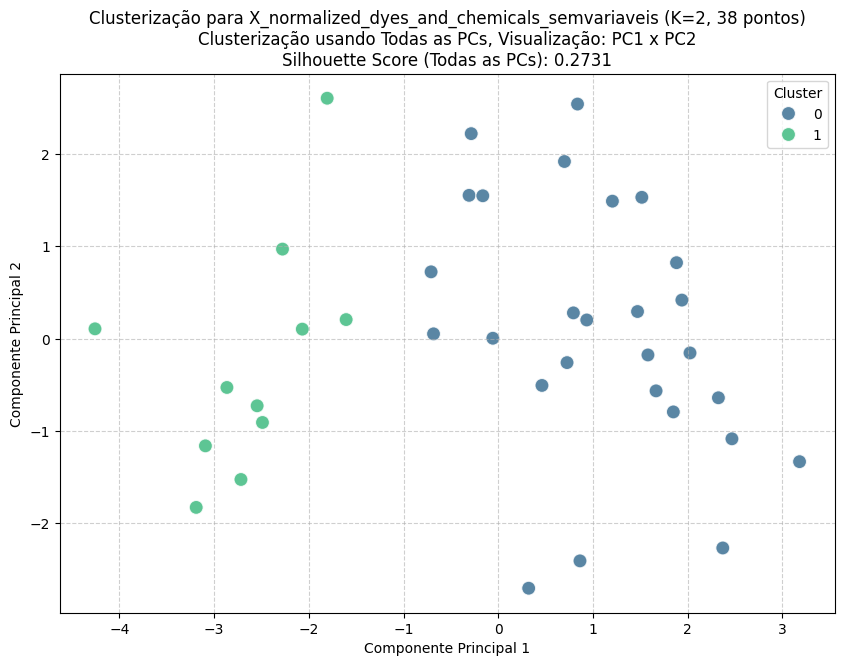


--- Processando dataset: X_normalized_packaging_semvariaveis com K=2 ---


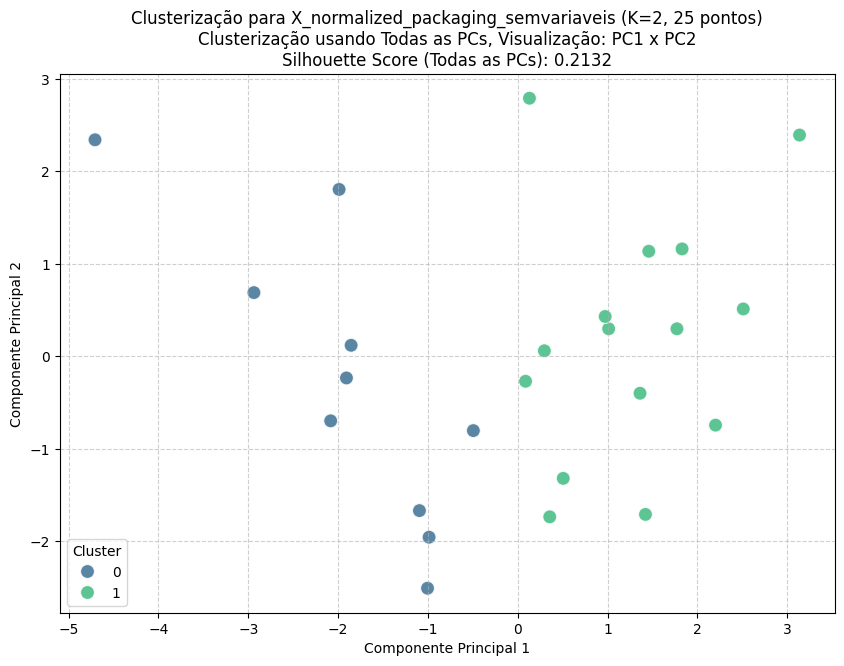


--- Processando dataset: X_normalized_elastic_and_trims_semvariaveis com K=2 ---


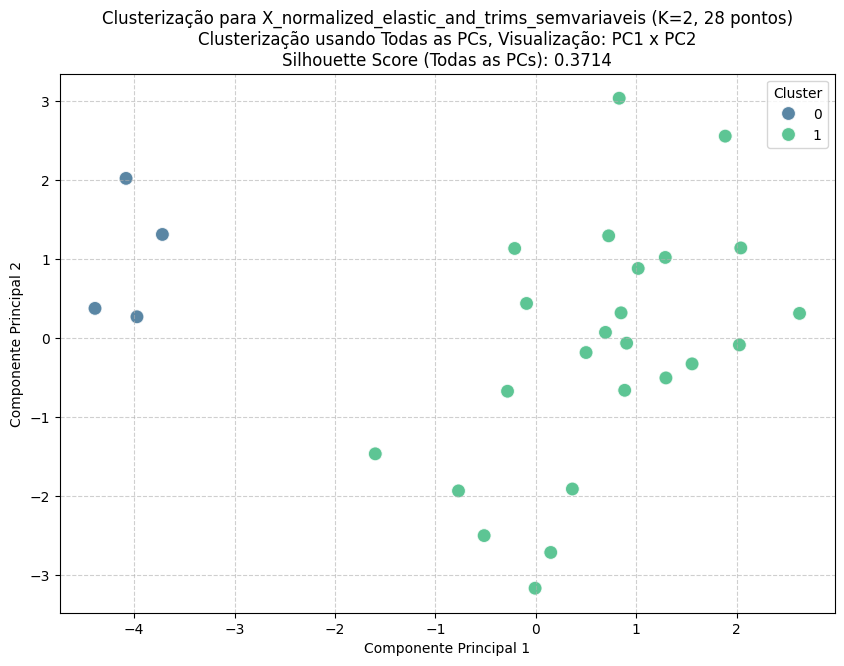


--- Processando dataset: X_normalized_polyester_fabric_semvariaveis com K=2 ---


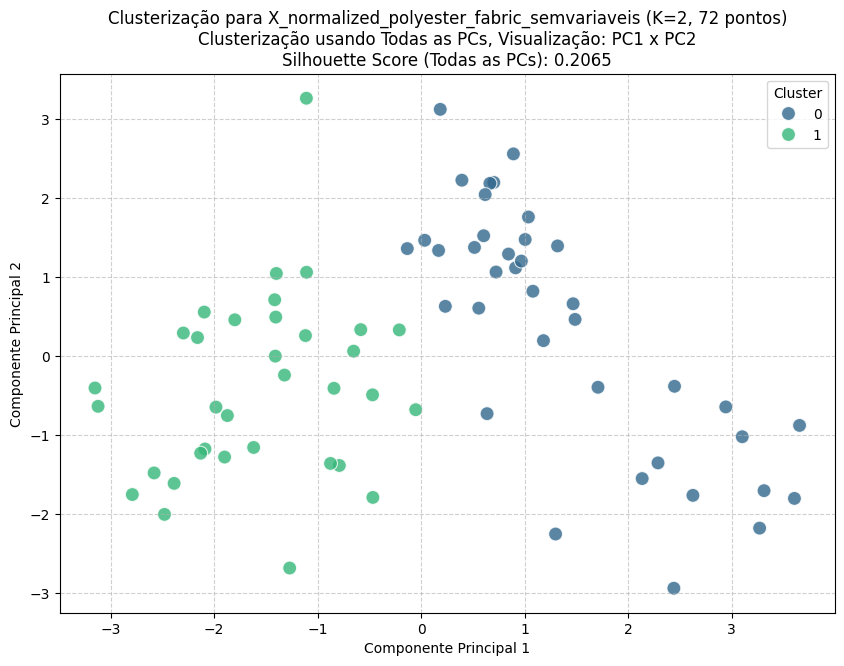


--- Processando dataset: X_normalized_labels_and_tags_semvariaveis com K=2 ---


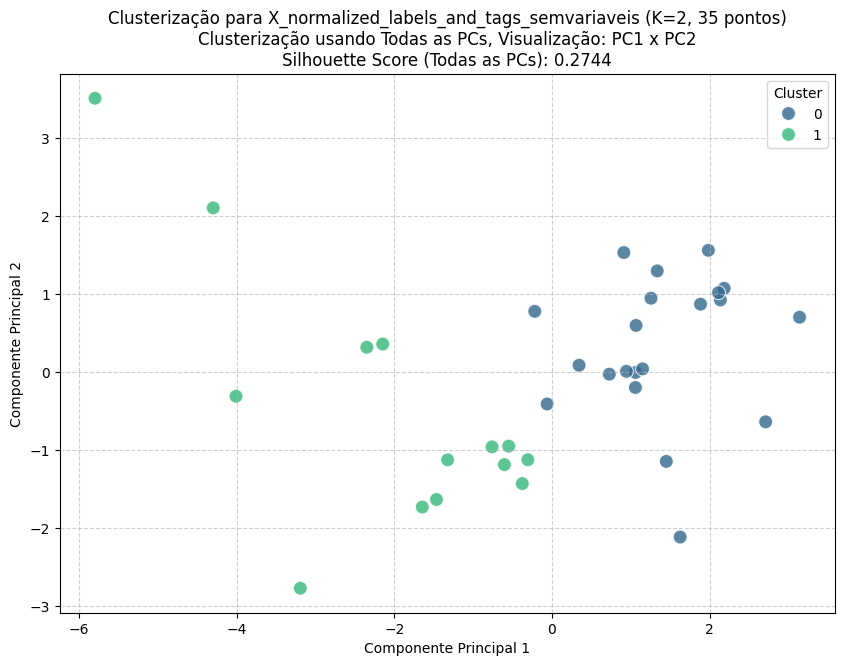


--- Processando dataset: X_normalized_zippers_semvariaveis com K=2 ---


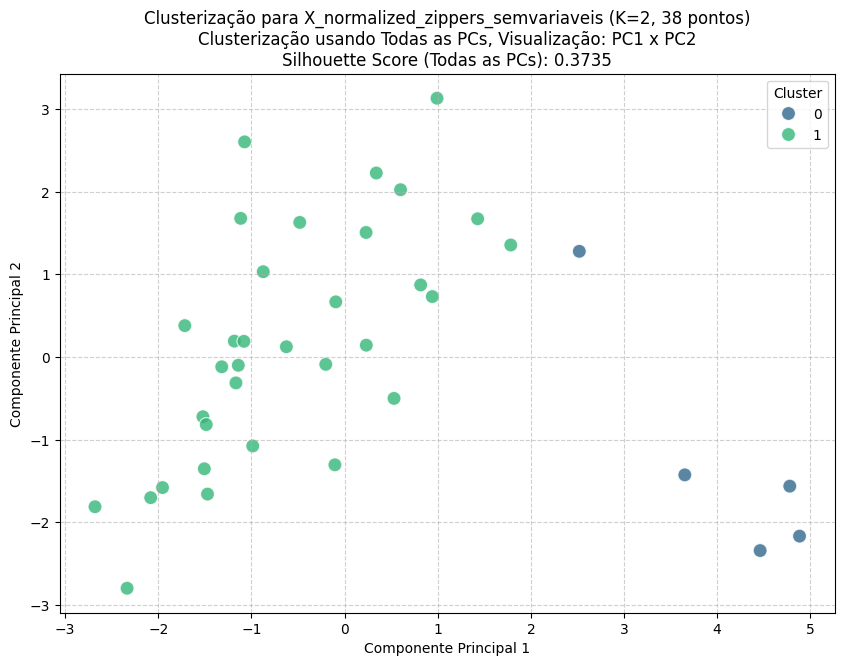


--- Processando dataset: X_normalized_denim_semvariaveis com K=2 ---


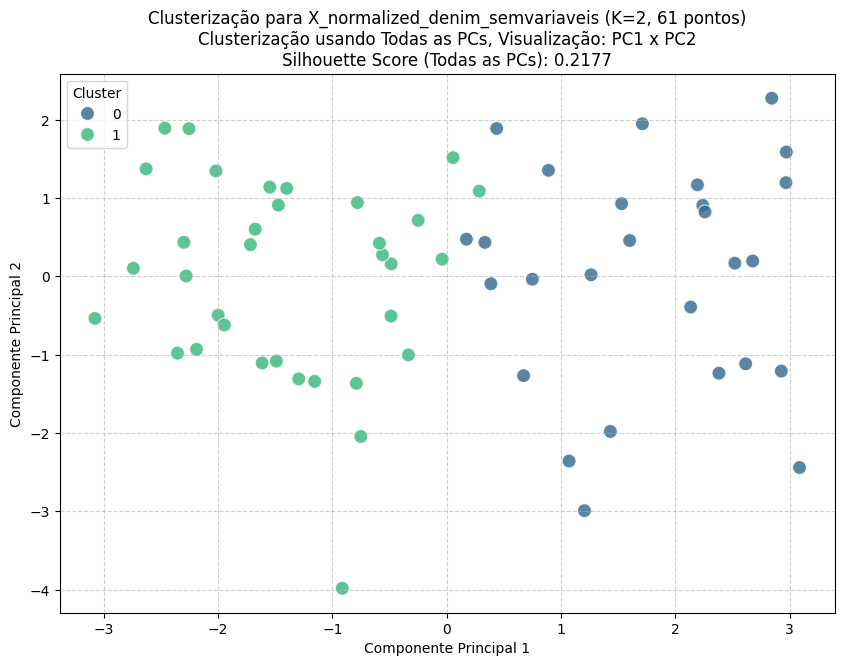


--- Processando dataset: X_normalized_thread_semvariaveis com K=2 ---


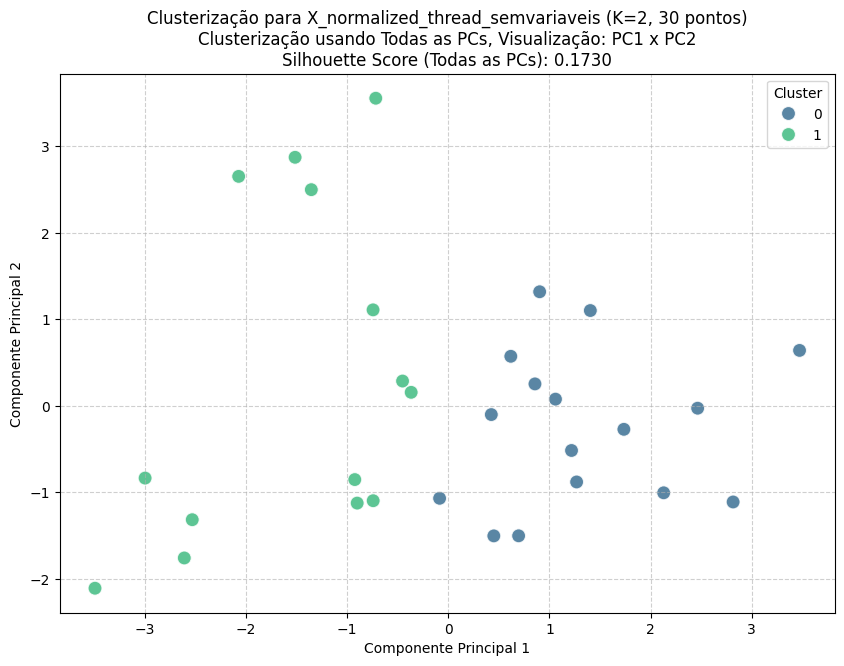

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Importar numpy para verificar NaNs
import pandas as pd # Garantir que pandas esteja importado para operações com DataFrame

k = 2 # Definindo K fixo em 2, conforme o contexto desta célula

# Itera sobre cada sub-dataset normalizado
for dataset_name, X_normalized_sub in normalized_datasets.items():
    print(f"\n--- Processando dataset: {dataset_name} com K={k} ---")

    # Verificar se o dataset não está vazio e tem amostras suficientes
    if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
        print(f"Aviso: Dataset '{dataset_name}' é muito pequeno ou vazio para PCA/Clusterização com K={k}. Pulando...")
        continue

    # === TRATAMENTO DE NaNs ===
    # Verificar se há NaNs e eliminá-los, se necessário
    if X_normalized_sub.isnull().sum().sum() > 0:
        print(f"Encontrado NaN no dataset '{dataset_name}'. Eliminando linhas com NaN...")
        X_normalized_sub = X_normalized_sub.dropna()
        # Após dropar, verificar novamente se o dataset ainda é válido para PCA/Clusterização
        if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
            print(f"Aviso: Após eliminar NaNs, o dataset '{dataset_name}' ficou muito pequeno ou vazio. Pulando...")
            continue
    # === FIM TRATAMENTO DE NaNs ===

    # Aplicar PCA para TODAS as componentes principais para a clusterização
    # n_components=None utiliza todas as componentes, até min(n_samples, n_features) - 1
    pca_full = PCA(n_components=None) # Usar todas as componentes para a clusterização
    X_pca_all_components = pca_full.fit_transform(X_normalized_sub)

    # K-Means Clustering usando TODAS as componentes principais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_sub = kmeans.fit_predict(X_pca_all_components) # Clusterizar usando todas as PCs

    # Calcular Silhouette Score usando TODAS as componentes principais
    if len(set(clusters_sub)) > 1 and X_pca_all_components.shape[0] > k:
        current_silhouette_score = silhouette_score(X_pca_all_components, clusters_sub)
        silhouette_str = f"Silhouette Score (Todas as PCs): {current_silhouette_score:.4f}"
    else:
        silhouette_str = "Silhouette Score: N/A (Não foi possível calcular ou apenas 1 cluster formado)"

    # Para visualização, usar apenas as duas primeiras componentes principais
    n_components_for_plot = min(2, X_pca_all_components.shape[1])
    if n_components_for_plot < 2:
        print(f"Aviso: Dataset '{dataset_name}' tem menos de 2 componentes para plotar. Pulando plotagem...")
        continue # Pula a plotagem, mas a clusterização já foi feita

    df_pca_plot = pd.DataFrame(
        X_pca_all_components[:, :n_components_for_plot], # Selecionar apenas as duas primeiras componentes para o plot
        columns=[f'PC{i+1}' for i in range(n_components_for_plot)],
        index=X_normalized_sub.index
    )

    # Adicionar os clusters ao DataFrame PCA para visualização
    df_pca_plot['Cluster'] = clusters_sub

    # Obter o número de pontos após o tratamento de NaNs
    num_points = df_pca_plot.shape[0]

    # Plotar os resultados
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=df_pca_plot['PC1'], # Primeira Componente Principal para visualização
        y=df_pca_plot['PC2'], # Segunda Componente Principal para visualização
        hue=df_pca_plot['Cluster'], # Colorir por cluster
        palette='viridis',
        s=100,
        alpha=0.8,
        edgecolor='w'
    )

    plt.title(f"Clusterização para {dataset_name} (K={k}, {num_points} pontos)\nClusterização usando Todas as PCs, Visualização: PC1 x PC2\n{silhouette_str}")
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **K=3**


--- Processando dataset: X_normalized_buttons_semvariaveis com K=3 ---


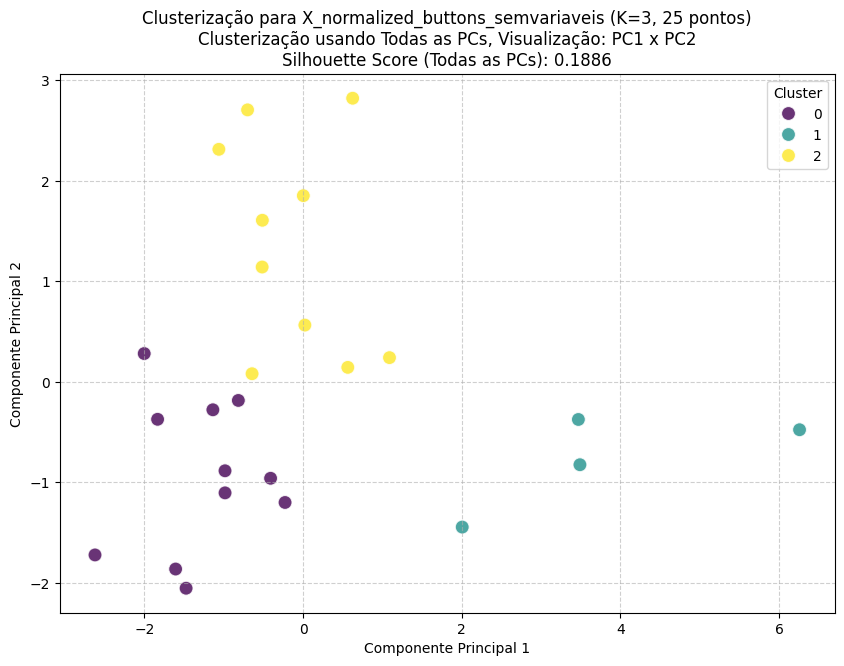


--- Processando dataset: X_normalized_cotton_fabric_semvariaveis com K=3 ---


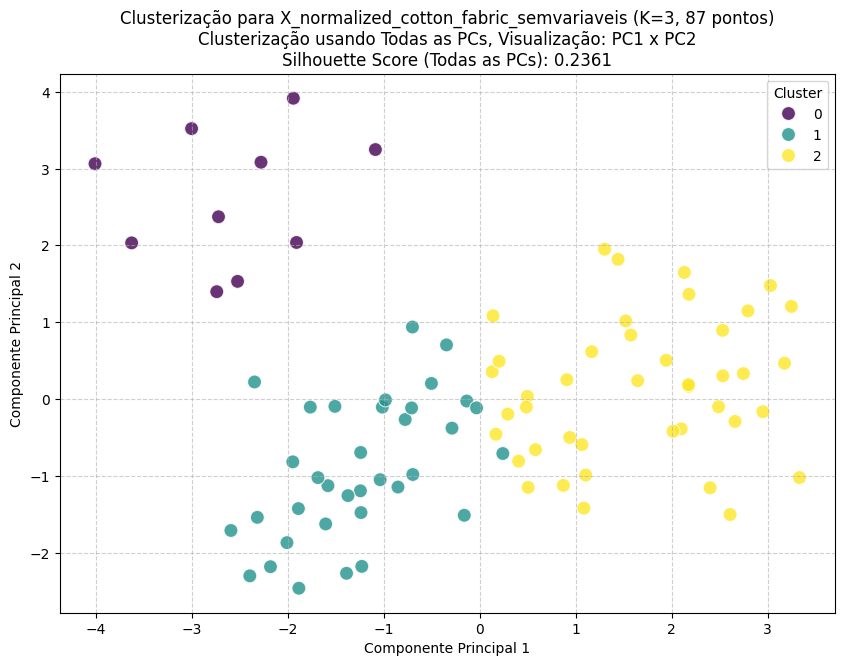


--- Processando dataset: X_normalized_yarn_semvariaveis com K=3 ---


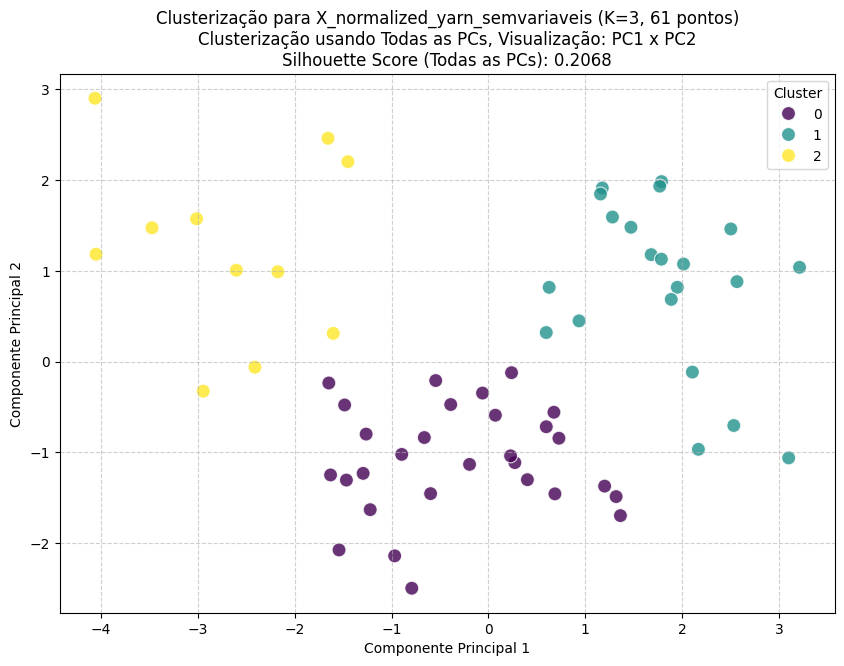


--- Processando dataset: X_normalized_dyes_and_chemicals_semvariaveis com K=3 ---


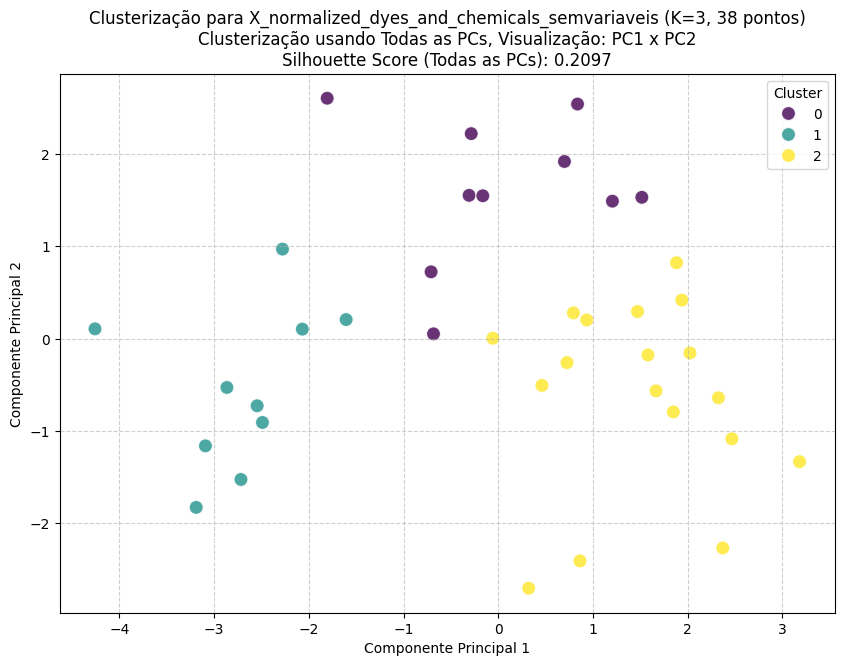


--- Processando dataset: X_normalized_packaging_semvariaveis com K=3 ---


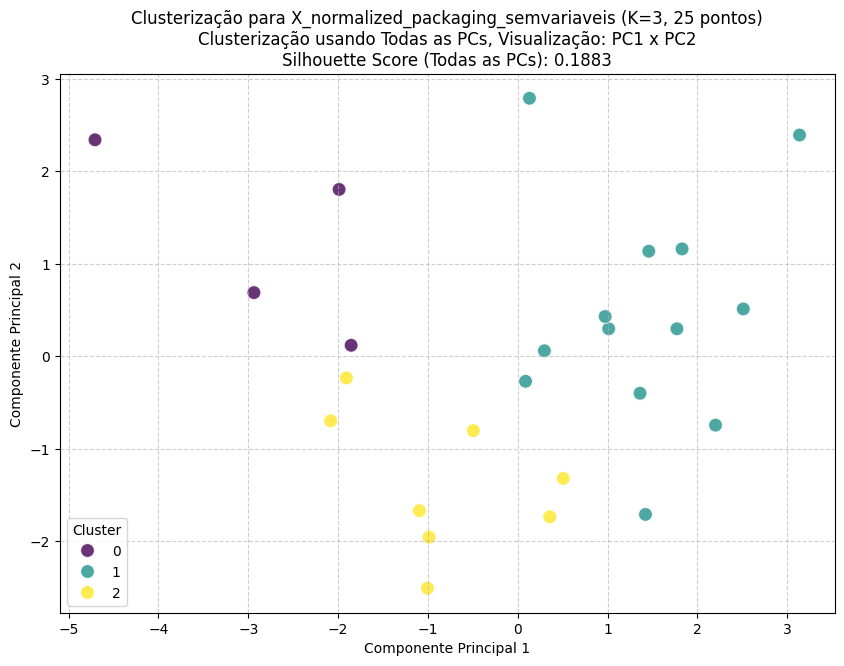


--- Processando dataset: X_normalized_elastic_and_trims_semvariaveis com K=3 ---


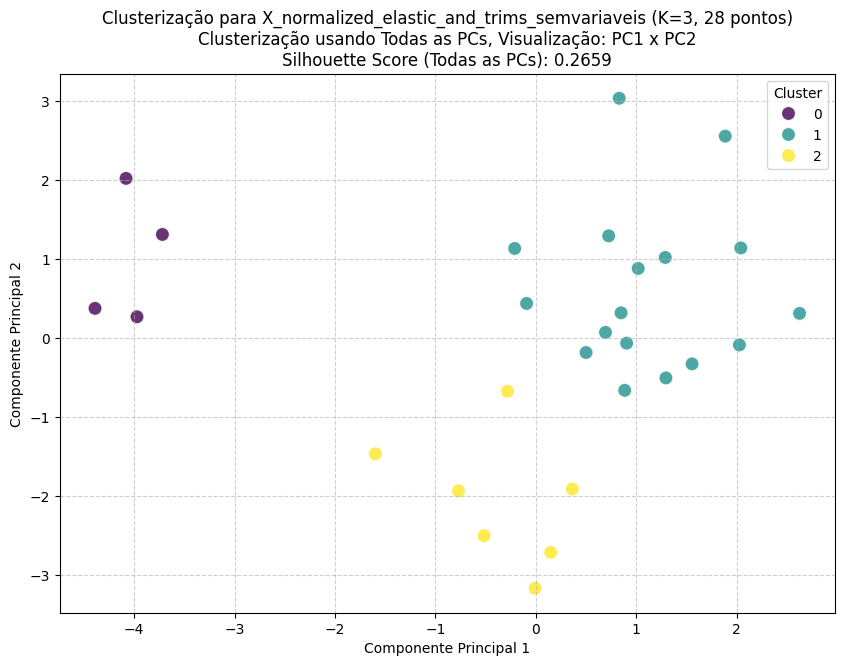


--- Processando dataset: X_normalized_polyester_fabric_semvariaveis com K=3 ---


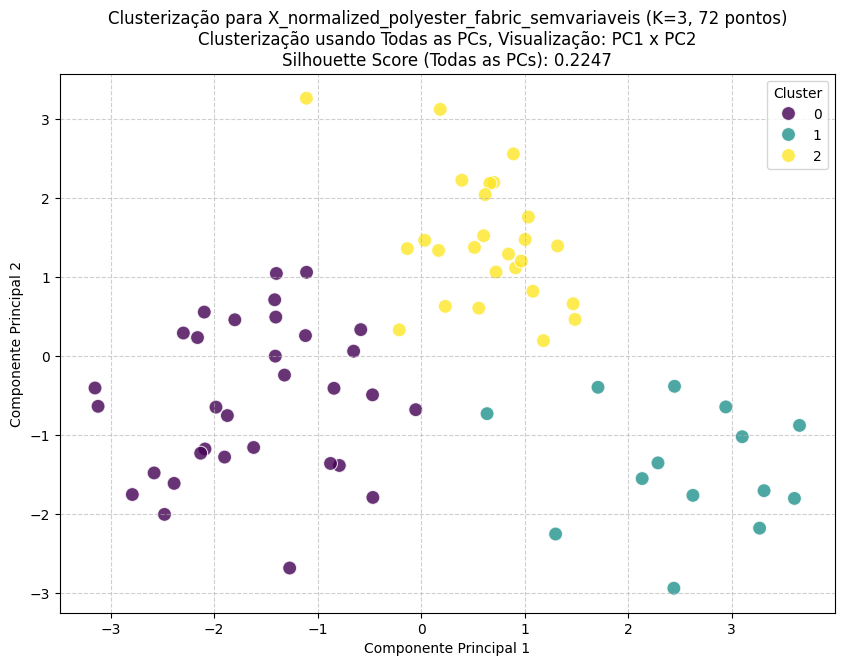


--- Processando dataset: X_normalized_labels_and_tags_semvariaveis com K=3 ---


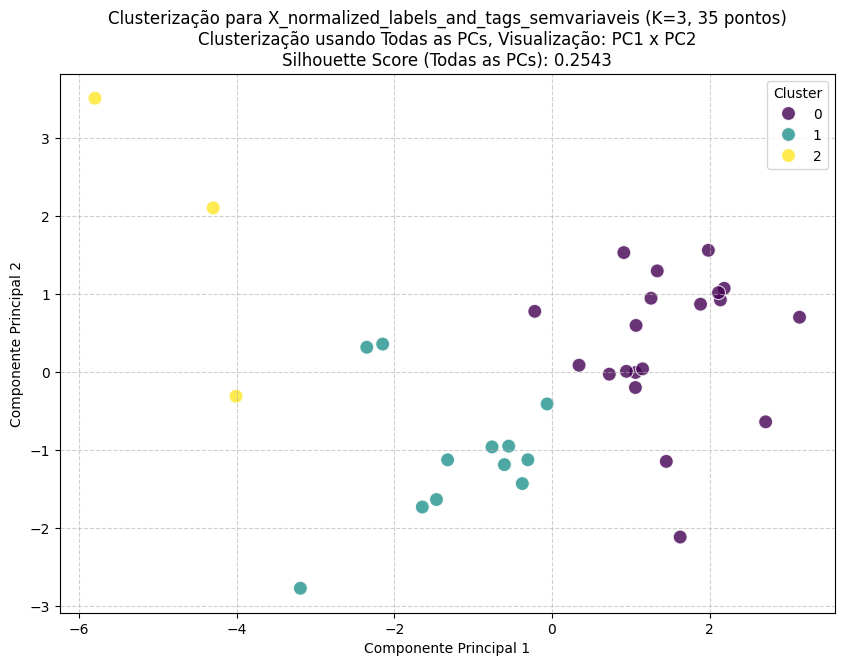


--- Processando dataset: X_normalized_zippers_semvariaveis com K=3 ---


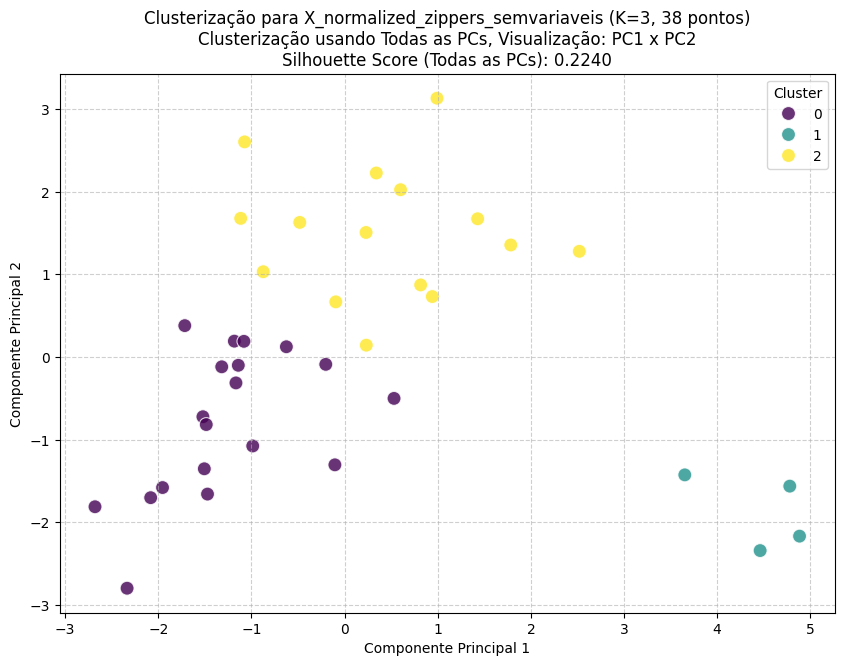


--- Processando dataset: X_normalized_denim_semvariaveis com K=3 ---


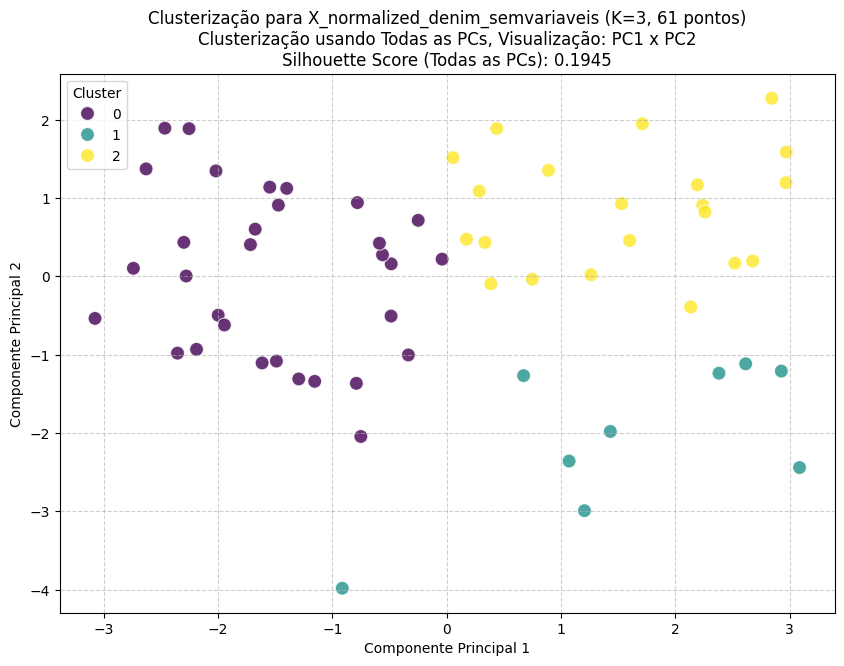


--- Processando dataset: X_normalized_thread_semvariaveis com K=3 ---


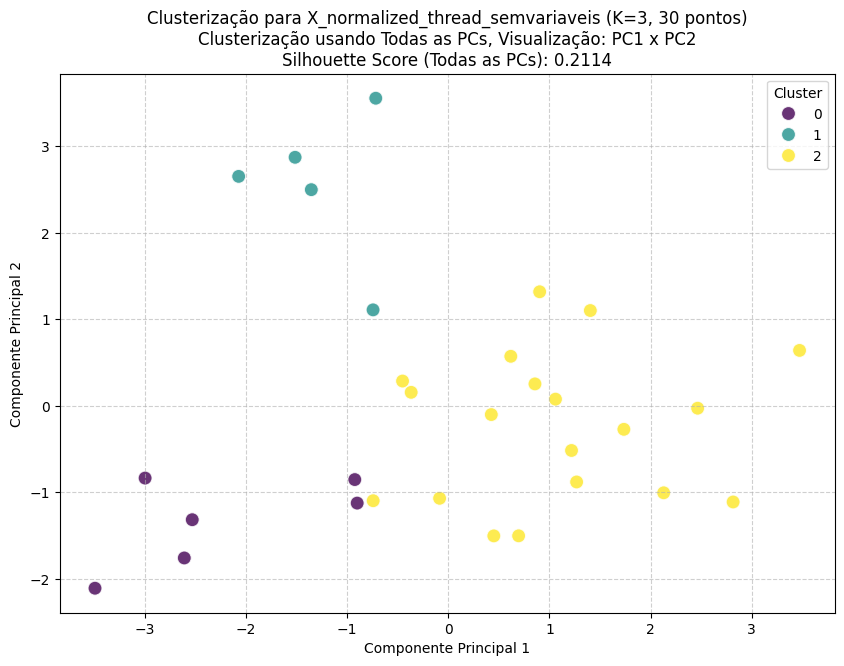

In [ ]:
k = 3 # Definindo K fixo em 3, conforme o contexto desta célula

# Itera sobre cada sub-dataset normalizado
for dataset_name, X_normalized_sub in normalized_datasets.items():
    print(f"\n--- Processando dataset: {dataset_name} com K={k} ---")

    # Verificar se o dataset não está vazio e tem amostras suficientes
    if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
        print(f"Aviso: Dataset '{dataset_name}' é muito pequeno ou vazio para PCA/Clusterização com K={k}. Pulando...")
        continue

    # === TRATAMENTO DE NaNs ===
    # Verificar se há NaNs e eliminá-los, se necessário
    if X_normalized_sub.isnull().sum().sum() > 0:
        print(f"Encontrado NaN no dataset '{dataset_name}'. Eliminando linhas com NaN...")
        X_normalized_sub = X_normalized_sub.dropna()
        # Após dropar, verificar novamente se o dataset ainda é válido para PCA/Clusterização
        if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
            print(f"Aviso: Após eliminar NaNs, o dataset '{dataset_name}' ficou muito pequeno ou vazio. Pulando...")
            continue
    # === FIM TRATAMENTO DE NaNs ===

    # Aplicar PCA para TODAS as componentes principais para a clusterização
    # n_components=None utiliza todas as componentes, até min(n_samples, n_features) - 1
    pca_full = PCA(n_components=None) # Usar todas as componentes para a clusterização
    X_pca_all_components = pca_full.fit_transform(X_normalized_sub)

    # K-Means Clustering usando TODAS as componentes principais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_sub = kmeans.fit_predict(X_pca_all_components) # Clusterizar usando todas as PCs

    # Calcular Silhouette Score usando TODAS as componentes principais
    if len(set(clusters_sub)) > 1 and X_pca_all_components.shape[0] > k:
        current_silhouette_score = silhouette_score(X_pca_all_components, clusters_sub)
        silhouette_str = f"Silhouette Score (Todas as PCs): {current_silhouette_score:.4f}"
    else:
        silhouette_str = "Silhouette Score: N/A (Não foi possível calcular ou apenas 1 cluster formado)"

    # Para visualização, usar apenas as duas primeiras componentes principais
    n_components_for_plot = min(2, X_pca_all_components.shape[1])
    if n_components_for_plot < 2:
        print(f"Aviso: Dataset '{dataset_name}' tem menos de 2 componentes para plotar. Pulando plotagem...")
        continue # Pula a plotagem, mas a clusterização já foi feita

    df_pca_plot = pd.DataFrame(
        X_pca_all_components[:, :n_components_for_plot], # Selecionar apenas as duas primeiras componentes para o plot
        columns=[f'PC{i+1}' for i in range(n_components_for_plot)],
        index=X_normalized_sub.index
    )

    # Adicionar os clusters ao DataFrame PCA para visualização
    df_pca_plot['Cluster'] = clusters_sub

    # Obter o número de pontos após o tratamento de NaNs
    num_points = df_pca_plot.shape[0]

    # Plotar os resultados
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=df_pca_plot['PC1'], # Primeira Componente Principal para visualização
        y=df_pca_plot['PC2'], # Segunda Componente Principal para visualização
        hue=df_pca_plot['Cluster'], # Colorir por cluster
        palette='viridis',
        s=100,
        alpha=0.8,
        edgecolor='w'
    )

    plt.title(f"Clusterização para {dataset_name} (K={k}, {num_points} pontos)\nClusterização usando Todas as PCs, Visualização: PC1 x PC2\n{silhouette_str}")
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **K=4**


--- Processando dataset: X_normalized_buttons_semvariaveis com K=4 ---


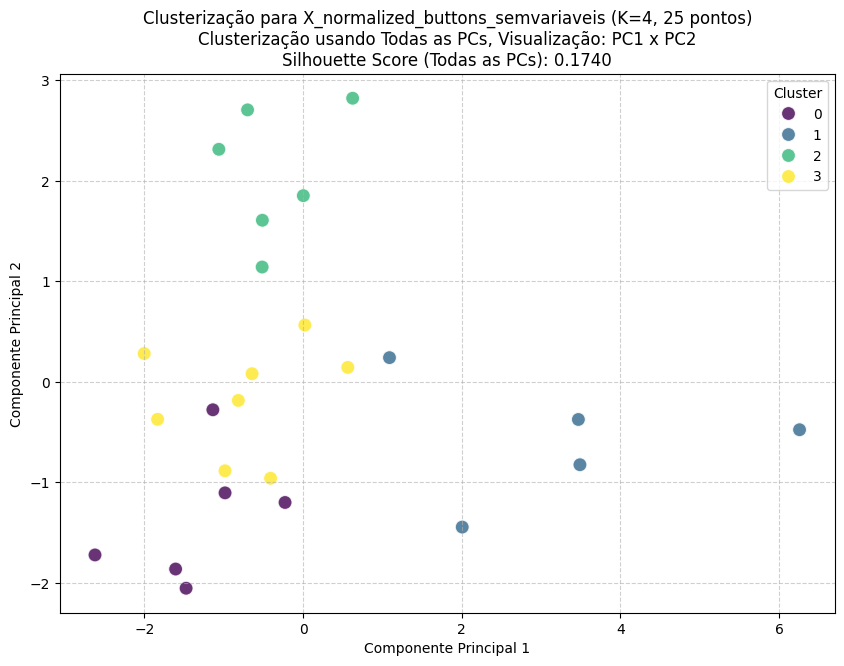


--- Processando dataset: X_normalized_cotton_fabric_semvariaveis com K=4 ---


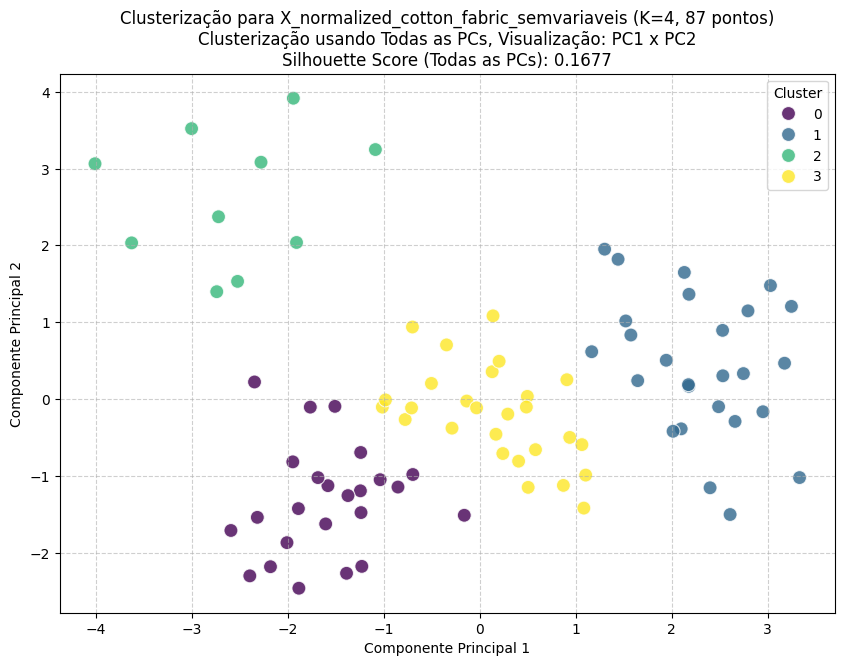


--- Processando dataset: X_normalized_yarn_semvariaveis com K=4 ---


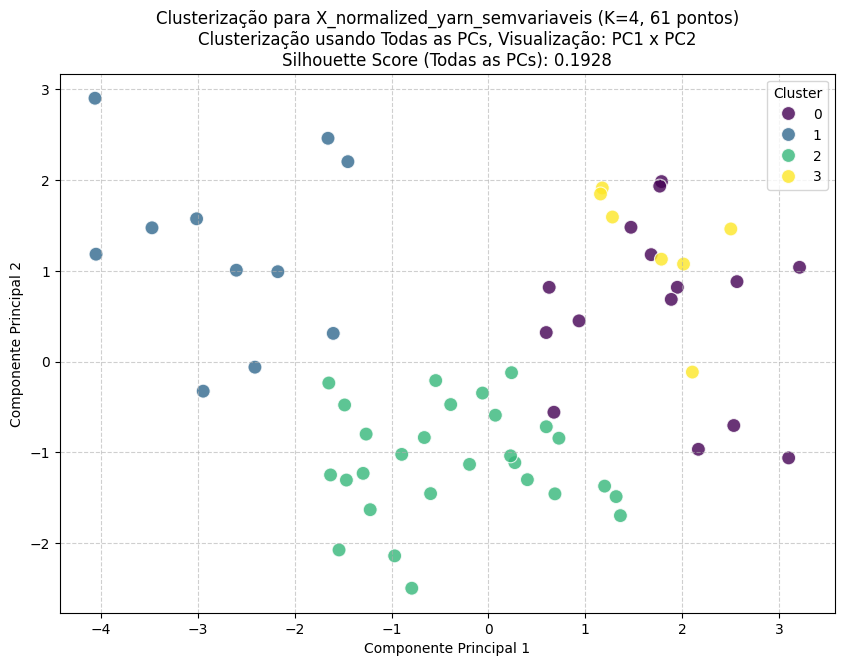


--- Processando dataset: X_normalized_dyes_and_chemicals_semvariaveis com K=4 ---


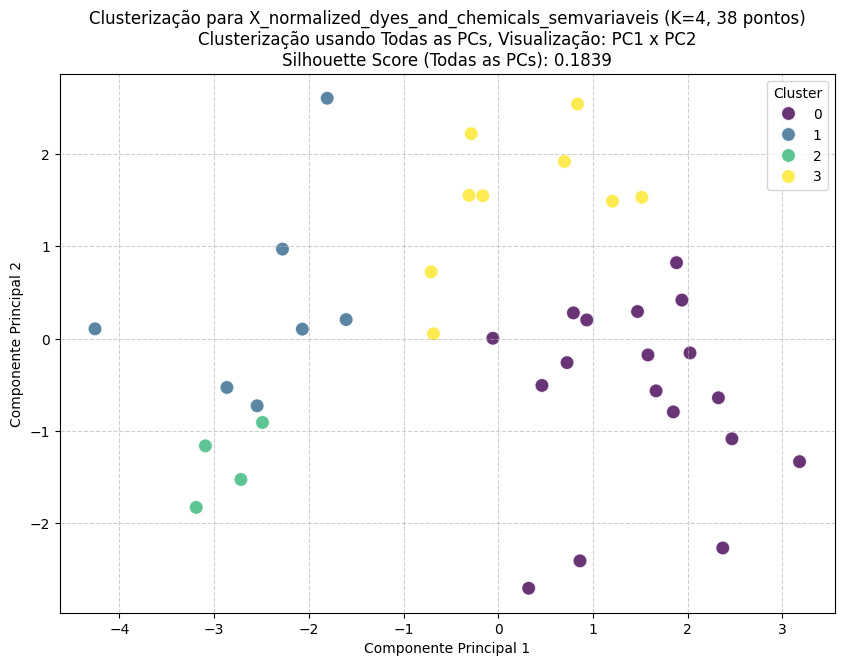


--- Processando dataset: X_normalized_packaging_semvariaveis com K=4 ---


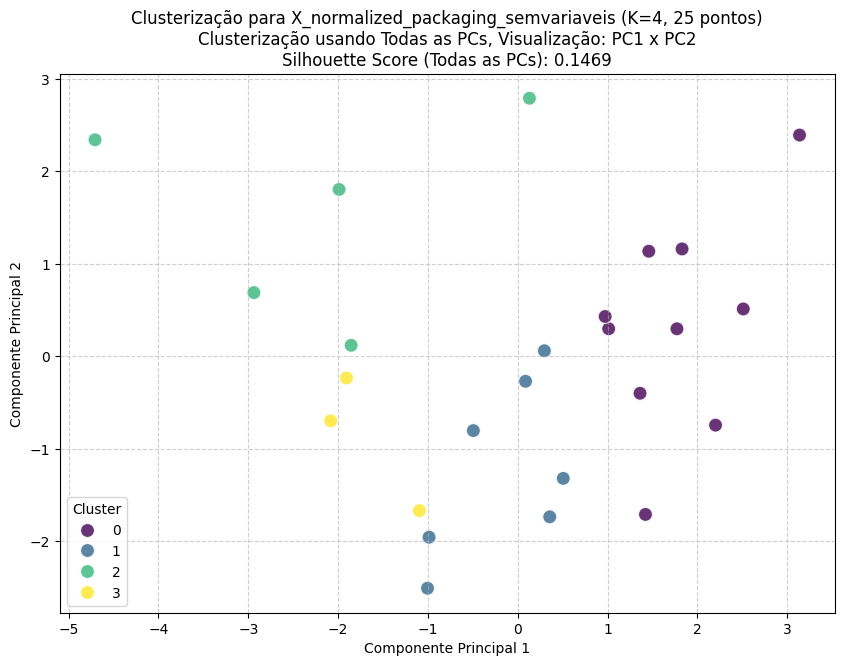


--- Processando dataset: X_normalized_elastic_and_trims_semvariaveis com K=4 ---


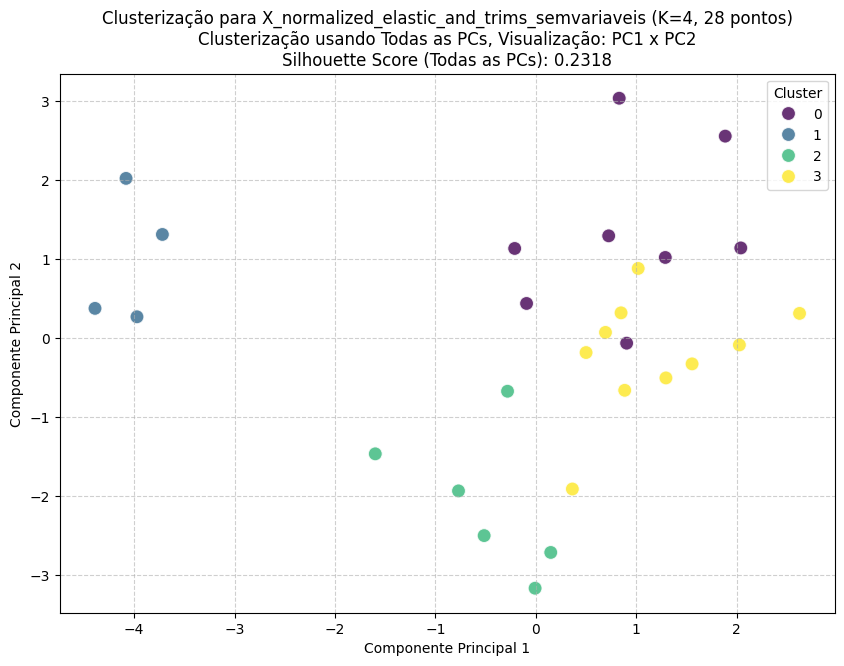


--- Processando dataset: X_normalized_polyester_fabric_semvariaveis com K=4 ---


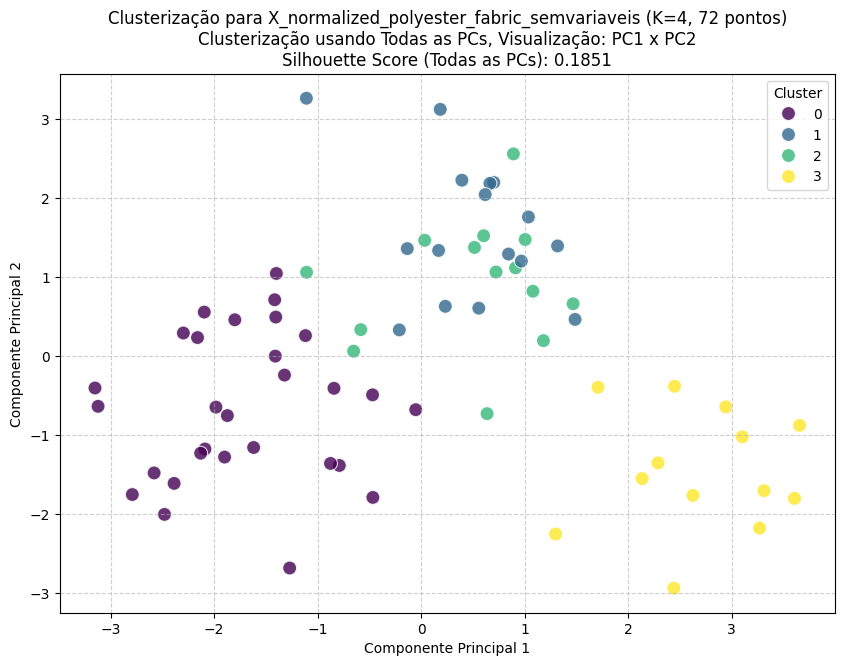


--- Processando dataset: X_normalized_labels_and_tags_semvariaveis com K=4 ---


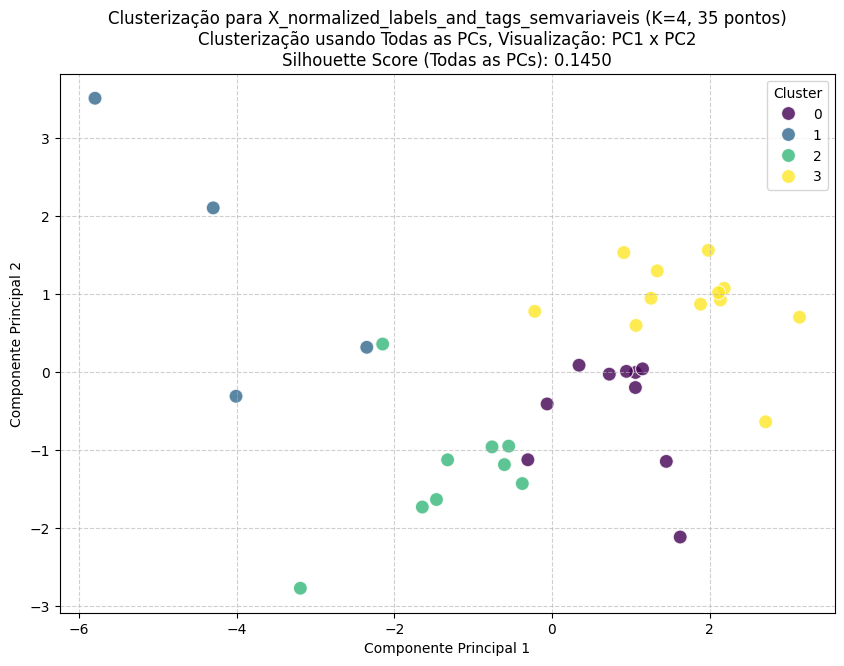


--- Processando dataset: X_normalized_zippers_semvariaveis com K=4 ---


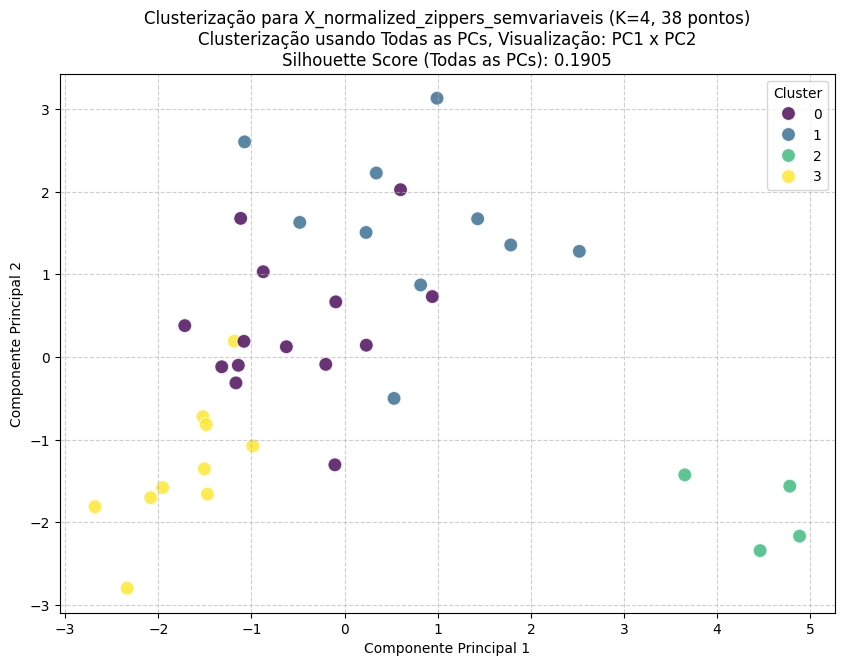


--- Processando dataset: X_normalized_denim_semvariaveis com K=4 ---


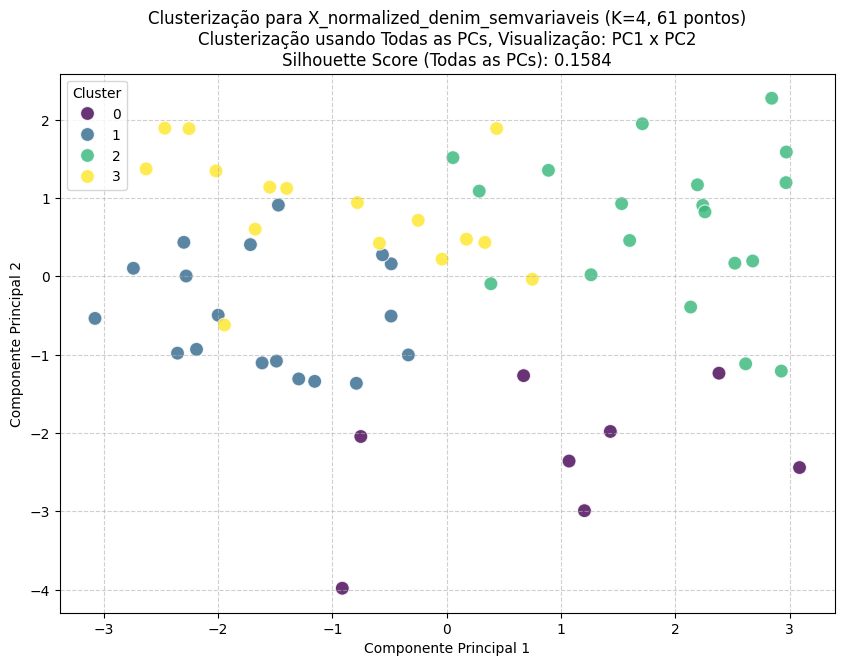


--- Processando dataset: X_normalized_thread_semvariaveis com K=4 ---


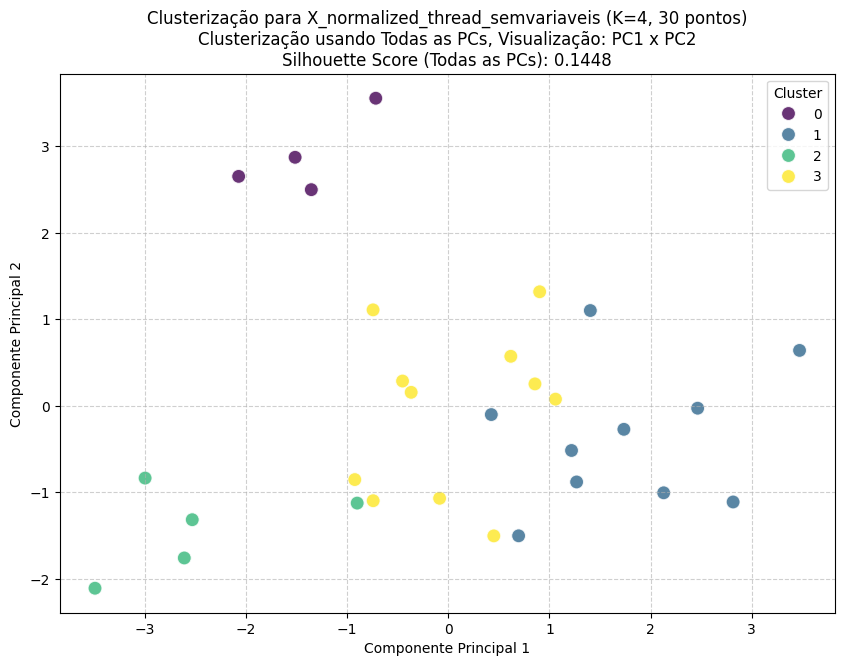

In [ ]:
k = 4 # Definindo K fixo em 4, conforme o contexto desta célula

# Itera sobre cada sub-dataset normalizado
for dataset_name, X_normalized_sub in normalized_datasets.items():
    print(f"\n--- Processando dataset: {dataset_name} com K={k} ---")

    # Verificar se o dataset não está vazio e tem amostras suficientes
    if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
        print(f"Aviso: Dataset '{dataset_name}' é muito pequeno ou vazio para PCA/Clusterização com K={k}. Pulando...")
        continue

    # === TRATAMENTO DE NaNs ===
    # Verificar se há NaNs e eliminá-los, se necessário
    if X_normalized_sub.isnull().sum().sum() > 0:
        print(f"Encontrado NaN no dataset '{dataset_name}'. Eliminando linhas com NaN...")
        X_normalized_sub = X_normalized_sub.dropna()
        # Após dropar, verificar novamente se o dataset ainda é válido para PCA/Clusterização
        if X_normalized_sub.empty or X_normalized_sub.shape[0] < k:
            print(f"Aviso: Após eliminar NaNs, o dataset '{dataset_name}' ficou muito pequeno ou vazio. Pulando...")
            continue
    # === FIM TRATAMENTO DE NaNs ===

    # Aplicar PCA para TODAS as componentes principais para a clusterização
    # n_components=None utiliza todas as componentes, até min(n_samples, n_features) - 1
    pca_full = PCA(n_components=None) # Usar todas as componentes para a clusterização
    X_pca_all_components = pca_full.fit_transform(X_normalized_sub)

    # K-Means Clustering usando TODAS as componentes principais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_sub = kmeans.fit_predict(X_pca_all_components) # Clusterizar usando todas as PCs

    # Calcular Silhouette Score usando TODAS as componentes principais
    if len(set(clusters_sub)) > 1 and X_pca_all_components.shape[0] > k:
        current_silhouette_score = silhouette_score(X_pca_all_components, clusters_sub)
        silhouette_str = f"Silhouette Score (Todas as PCs): {current_silhouette_score:.4f}"
    else:
        silhouette_str = "Silhouette Score: N/A (Não foi possível calcular ou apenas 1 cluster formado)"

    # Para visualização, usar apenas as duas primeiras componentes principais
    n_components_for_plot = min(2, X_pca_all_components.shape[1])
    if n_components_for_plot < 2:
        print(f"Aviso: Dataset '{dataset_name}' tem menos de 2 componentes para plotar. Pulando plotagem...")
        continue # Pula a plotagem, mas a clusterização já foi feita

    df_pca_plot = pd.DataFrame(
        X_pca_all_components[:, :n_components_for_plot], # Selecionar apenas as duas primeiras componentes para o plot
        columns=[f'PC{i+1}' for i in range(n_components_for_plot)],
        index=X_normalized_sub.index
    )

    # Adicionar os clusters ao DataFrame PCA para visualização
    df_pca_plot['Cluster'] = clusters_sub

    # Obter o número de pontos após o tratamento de NaNs
    num_points = df_pca_plot.shape[0]

    # Plotar os resultados
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        x=df_pca_plot['PC1'], # Primeira Componente Principal para visualização
        y=df_pca_plot['PC2'], # Segunda Componente Principal para visualização
        hue=df_pca_plot['Cluster'], # Colorir por cluster
        palette='viridis',
        s=100,
        alpha=0.8,
        edgecolor='w'
    )

    plt.title(f"Clusterização para {dataset_name} (K={k}, {num_points} pontos)\nClusterização usando Todas as PCs, Visualização: PC1 x PC2\n{silhouette_str}")
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Cluster')
    plt.show()

# **Resultados:**

Para cada produto, ao aplicar PCA, os melhores números de clusters seriam:

Buttons: K=2

Cotton Fabric: K=3

Denim: K=2

Dyes and Chemicals: K=2

Elastic and Trims: K=2

Labels and Tags: K=2

Packaging: K=2

Polyster Fabric: K=3

Thread: K=3

Yarn: K=3

Zippers: K=2